# Modelado Multiescala de Derivados de Protoporfirina IX y Sitio Activo de β-Hematina mediante Redes Neuronales de Grafos (GNN)

$\require{mhchem}$
Eduardo Henao Restrepo, Carlos Mario García Álvarez

In [1]:
# === INSTALACIÓN DE DEPENDENCIAS Y PAQUETES ===

# rdkit: Herramienta estándar para quimioinformática y manipulación de moléculas 2D/3D
# py3Dmol: Visualizador interactivo 3D para notebooks de Jupyter
%pip install -q rdkit py3Dmol tabulate

# torch-dftd: Correcciones de dispersión DFT-D3 para PyTorch
# torch_geometric: Biblioteca principal para Redes Neuronales de Grafos (GNN)
%pip install -q torch-dftd torch_geometric

# mace-torch: Potenciales interatómicos basados en aprendizaje profundo de tensores equivariantes
# ase: Atomic Simulation Environment para la creación y manipulación de estructuras moleculares
%pip install -q mace-torch ase

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import copy
import random
import warnings

warnings.filterwarnings("ignore", category=FutureWarning, module="torch")
warnings.filterwarnings("ignore", category=UserWarning, module="e3nn")
warnings.filterwarnings("ignore", category=UserWarning, module="mace")
warnings.filterwarnings("ignore", category=UserWarning, module="torch_dftd")

# === Cómputo científico y grafos ===
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
import torch
import torch.nn as nn
import torch.nn.functional as fn
from tqdm.auto import tqdm

# === PyTorch Geometric ===
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import CGConv, global_add_pool

# === Scikit-Learn (Líneas base y métricas) ===
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# === Quimioinformática y visualización molecular ===
import py3Dmol
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from rdkit.Chem.Draw import IPythonConsole

IPythonConsole.ipython_useSVG = True

# === Simulación atomística 3D (ASE + MACE) ===
from ase import Atoms
from ase.constraints import FixAtoms, FixBondLength
from ase.optimize import BFGS
from ase.io import write
from mace.calculators import mace_mp

# === Utilidades de despliegue ===
from IPython.display import Markdown, display
from tabulate import tabulate


def dMarkdown(text: str) -> None:
    """Muestra texto enriquecido en formato Markdown."""
    display(Markdown(text))


def dM_table(datos_tabla, headers) -> None:
    """Renderiza una tabla en formato Markdown."""
    dMarkdown(tabulate(datos_tabla, headers=headers, tablefmt="pipe"))


# === Reproducibilidad y dispositivo ===
SEED = 137
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dMarkdown(f"**Entorno inicializado** | Semilla: `{SEED}` | Dispositivo activo: `{DISPOSITIVO}`")

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.


**Entorno inicializado** | Semilla: `137` | Dispositivo activo: `cuda`

## Contexto Fisicoquímico y Biológico del Sistema Molecular

El modelado multiescala de este cuaderno se centra en la familia estructural de la **protoporfirina IX (PPIX)** y su derivado cristalino de hierro, la **$\beta$-hematina** (análogo sintético de la **hemozoína** biológica):

1. **Protoporfirina IX ($\ce{C34H34N4O4}$):** Es un macrociclo tetrapirrólico planar compuesto por cuatro anillos de pirrol unidos por puentes metino ($\ce{=CH-}$), lo que genera un sistema conjugado aromático de $18\;\pi$-electrones (regla de Hückel, $4n+2$ con $n=4$). Sus ocho posiciones periféricas $\beta$-pirrólicas contienen cuatro grupos metilo ($\ce{-CH3}$), dos grupos vinilo ($\ce{-CH=CH2}$) conjugados con el macrociclo y dos cadenas laterales de ácido propiónico ($\ce{-CH2-CH2-COOH}$). La deslocalización electrónica a través del anillo confiere alta rigidez estructural, absorción óptica intensa (bandas de Soret y Q) y sensibilidad energética frente a la identidad y posición relativa (regioquímica) de los sustituyentes periféricos.
2. **Grupo Hemo y Hematina ($\text{Fe(II)/Fe(III)-PPIX}$):** Al desprotonarse los dos nitrógenos pirrólicos internos, la cavidad tetradentada $\ce{N4}$ coordina un átomo de hierro. Durante la fase intraeritrocitaria de parásitos hematófagos como *Plasmodium falciparum* (agente de la malaria) o *Schistosoma*, la digestión proteolítica de la hemoglobina libera grandes cantidades de hemo libre en la vacuola digestiva ácida, donde el $\ce{Fe(II)}$ se oxida rápidamente a $\ce{Fe(III)}$ (ferriprotoporfirina IX o hematina). En estado libre, esta especie es lipofílica y altamente citotóxica: inhibe enzimas parasitarias clave, se inserta en las bicapas lipídicas reduciendo su fluidez, sensibiliza la membrana eritrocitaria a la lisis mediada por $\ce{H2O2}$ y promueve la generación de especies reactivas de oxígeno (radicales superóxido e hidroxilo) que desencadenan la peroxidación lipídica.
3. **β-Hematina y Hemozoína:** Para neutralizar el estrés oxidativo y regular su metabolismo de hierro, el parásito biocristaliza la hematina en **hemozoína**. A diferencia de un polímero covalente clásico, la $\beta$-hematina/hemozoína es un cristal molecular ensamblado a partir de **dímeros recíprocos**: el grupo carboxilato de una cadena propiónica se coordina axialmente al centro $\ce{Fe(III)}$ de una segunda unidad mediante un enlace $\ce{Fe-O}$, dejando al hierro en una coordinación piramidal de base cuadrada (pentacoordinado). Estos dímeros se empaquetan mediante puentes de hidrógeno entre las cadenas propiónicas libres e interacciones de apilamiento $\ce{\pi-\pi}$ entre los macrociclos.
4. **Significado biológico ampliado y relevancia farmacológica:** Estudios recientes mediante microscopía electrónica de transmisión (TEM) y transcriptómica (*Sun et al., Parasites & Vectors, 2025*) demuestran que la hemozoína no es un mero residuo inerte de detoxificación: se nuclea íntimamente asociada a una **matriz lipídica**, participa en el equilibrio dinámico de almacenamiento de hierro/hemo entre las etapas de trofozoíto y esquizonte, facilita el remodelado oxidativo de ácidos grasos insaturados del hospedero necesarios para formar membranas de nuevos merozoitos y altera la función fagocítica de macrófagos tras la ruptura del eritrocito. Por ello, interferir con el equilibrio hemo-hemozoína (mediante inhibidores de biocristalización o fármacos como las artemisininas, que forman aductos con el hemo) constituye uno de los mecanismos antimaláricos más efectivos.

# Parte C — Pregunta abierta: una GNN para su tesis

Piense en un problema de su tesis, o de su área, que se pueda plantear como aprendizaje sobre grafos. La parte C es individual y tiene dos entregables: el **diseño** de la idea y una **implementación de prueba**. En clase (15 min) se escribe el diseño y se empieza el prototipo; el prototipo se termina después de la sesión, en el plazo que fije el docente.

## C1. Diseño
Responda en la celda siguiente, en unas 10-15 líneas:

1. **El sistema como grafo.** ¿Qué son los nodos y las aristas? ¿Qué atributos tienen? ¿El grafo es fijo o depende de la geometría (como en MACE)?
2. **La tarea.** ¿Es de nodo, de arista o de grafo? ¿Qué se predice y qué lectura usaría (suma, media u otra) y por qué?
3. **Las simetrías.** ¿Qué debe ser invariante o equivariante: permutaciones, rotaciones, traslaciones, otra simetría del problema?
4. **Los datos.** ¿De dónde salen (simulación, experimento, base de datos)? ¿Cuántos hay o podría generar?
5. **La evaluación.** ¿Contra qué línea base compararía, con qué métrica y cómo separaría entrenamiento y prueba sin filtrar información?
# Para la exposición (5 min)

El docente asigna a cada equipo una parte. Prepare **una tabla o figura** y responda:

- **A1.** ¿Mejora la GCN a la regresión logística del Lab 14? ¿Dónde sigue fallando y por qué?
- **A2.** ¿Por qué la lectura de media y no la de suma para $K$? ¿Qué cristales predice peor la red?
- **B.** ¿Concuerda MACE-MP-0 con DFT? ¿Por qué no del todo?

Al final, tres o cuatro estudiantes presentan su propuesta de la parte C en 1 minuto.

Este cuaderno desarrolla y valida un prototipo en dos niveles de representación sobre el sistema **protoporfirina IX (PPIX) / $\beta$-hematina (hemozoína)** [PubChem CID 4971](https://pubchem.ncbi.nlm.nih.gov/compound/4971#section=3D-Conformer):

1. **Enfoque topológico 2D (`PPIXNet`, PyTorch Geometric):** predicción de una energía extensiva sobre grafos moleculares construidos desde SMILES con RDKit, capturando acoplamientos regioquímicos en las 8 posiciones $\beta$-pirrólicas con invariancia permutacional $S_N$.
2. **Enfoque geométrico 3D equivariante (`MACE-MP-0 + D3`, ASE):** evaluación de simetrías $E(3) \times S_N$, adsorción y perfil relajado de ruptura del enlace $\ce{O-O}$ de $\ce{H2O2}$ sobre el centro $\ce{Fe(III)}$ pentacoordinado expuesto de la $\beta$-hematina.

## C1. Diseño del Sistema de Aprendizaje sobre Grafos

1. **El sistema como grafo:**
   * *Nivel molecular (2D):* cada derivado de PPIX se representa desde su SMILES mediante RDKit como un grafo covalente no dirigido y fijo. Los nodos son átomos pesados ($\text{C, N, O, F, Cl}$) con $\mathbf{x}_u \in \mathbb{R}^8$ (one-hot elemental, grado normalizado, pertenencia a anillo y número de enlaces $\pi$); las aristas son enlaces covalentes con $\mathbf{e}_{uv} \in \mathbb{R}^4$ (orden simple/doble/triple e indicador de anillo).
   * *Nivel catalítico (3D):* el sitio activo de $\beta$-hematina ($\ce{FeC20N4H12 \cdot HCOO}^-$) interactuando con $\ce{H2O2}$ se modela como grafo geométrico dependiente de las coordenadas atómicas dentro de un radio de corte (arquitectura equivariante MACE).
2. **La tarea:** regresión a nivel de grafo de una energía extensiva $E(G) = \sum_{u \in V} \epsilon_u$. Se emplea **lectura aditiva sobre contribuciones atómicas** (`global_add_pool` aplicado *después* de proyectar cada nodo a $\epsilon_u \in \mathbb{R}$), garantizando escalamiento exacto con el tamaño del sistema $N$. En el modelo 3D, las fuerzas se obtienen como gradientes conservativos $\mathbf{F}_i = -\nabla_{\mathbf{r}_i} E$.
3. **Las simetrías:**
   * *Grafo 2D:* invariancia estricta bajo permutaciones $S_N$ de nodos y aristas ($E(P\cdot G) = E(G)$), asegurando independencia frente a la numeración del SMILES; la invariancia $E(3)$ se cumple trivialmente al no usar coordenadas cartesianas.
   * *Grafo 3D:* invariancia de $E$ y equivarianza vectorial de $\mathbf{F}$ bajo el grupo $E(3) \times S_N$ (rotaciones, traslaciones y permutaciones).
4. **Los datos:** en la tesis completa provendrán de bibliotecas SMILES (PubChem/ChEMBL) etiquetadas con DFT ($\text{PBE+D3(BJ)}$ o funcionales híbridos con control de espín) y ensayos de inhibición de $\beta$-hematina ($10^2-10^4$ estructuras). Para este prototipo se construye explícitamente un **conjunto sintético controlado de 301 moléculas** (PPIX nativa + 60 familias composicionales $\times$ 5 regioisómeros canónicamente distintos) cuya energía objetivo incluye acoplamientos regioquímicos de hasta 3 saltos.
5. **La evaluación:** `PPIXNet` (3 capas `CGConv` con conexiones residuales, `LayerNorm` y lectura atómica centrada en $\mu_{\mathrm{atom}}$) se compara contra tres líneas base (Dummy, Ridge y Random Forest sobre descriptores composicionales) midiendo **MAE**, **RMSE** y **$R^2$**. Para impedir fuga entre regioisómeros de idéntica fórmula, la partición **Entrenamiento / Validación / Prueba (64 / 16 / 20 %)** se realiza con `GroupShuffleSplit` por firma composicional, ajustando escaladores y $\mu_{\mathrm{atom}}$ exclusivamente en entrenamiento.

### Significado físico de la representación molecular como grafo 2D

Desde la química física, representar derivados de PPIX como un **grafo molecular multirrelacional no dirigido** $G = (V, E)$ captura el acoplamiento electrónico y estérico local sin depender de la enumeración arbitraria de la cadena SMILES:

* **Nodos ($V$, átomos pesados) y atributos $\mathbf{x}_u \in \mathbb{R}^8$:** La identidad elemental ($\text{C, N, O, F, Cl}$) codifica la electronegatividad y afinidad electrónica; el grado normalizado refleja la hibridación y saturación local; la pertenencia a anillo distingue el núcleo aromático conjugado de las cadenas laterales flexibles; y el número de enlaces $\pi$ cuantifica la capacidad de conjugación electrónica.
* **Aristas ($E$, enlaces covalentes) y atributos $\mathbf{e}_{uv} \in \mathbb{R}^4$:** El orden de enlace (simple, doble, triple) y el indicador de anillo codifican la fuerza del enlace covalente y la vía de propagación de efectos inductivos y mesoméricos (resonancia).
* **Por qué los descriptores composicionales fallan en regioisómeros:** Dos regioisómeros de PPIX poseen exactamente la misma fórmula molecular y masa molar, pero ubicar sustituyentes polares o conjugados (como $\ce{-F}$, $\ce{-Cl}$, $\ce{-OH}$ o $\ce{-CH=CH2}$) en posiciones $\beta$-pirrólicas adyacentes (separadas por 1 a 3 enlaces) modifica la densidad electrónica local, la repulsión estérica y la energía de estabilización molecular $E(G)$. Una GNN de paso de mensajes con alcance de 3 saltos captura explícitamente esta conectividad, mientras que la lectura aditiva (`global_add_pool`) respeta la **extensividad termodinámica** de la energía ($E = \sum_{u \in V} \epsilon_u$).

# Parte I — GNN Topológica 2D para Derivados de Protoporfirina IX (`PPIXNet`)

## 1. Validación estructural 2D y 3D de la Protoporfirina IX
Partimos del SMILES neutro en forma Kekulé de la PPIX ($\ce{C34H34N4O4}$, 42 átomos pesados y 46 enlaces covalentes) y definimos una plantilla paramétrica con las 8 posiciones $\beta$-pirrólicas sustituibles (`R1`..`R8`).

### Estructura 2D de la Protoporfirina IX (RDKit)
Átomos pesados: **42** | Enlaces covalentes: **46**

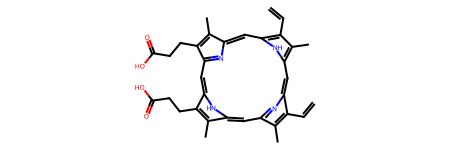

### Confórmero 3D interactivo de la Protoporfirina IX (MMFF94 + py3Dmol)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [3]:
# Definir la cadena SMILES de la Protoporfirina IX y su plantilla para generar derivados
SMILES_PPIX = (
    "C1(C)=C(C2=CC3=NC(=CC4=C(C(=C(N4)C=C5C(=C(C(=N5)C=C1N2)C)C=C)C)C=C)"
    "C(=C3CCC(=O)O)C)CCC(=O)O"
)
TEMPLATE_PPIX = (
    "C1({R1})=C(C2=CC3=NC(=CC4=C(C(=C(N4)C=C5C(=C(C(=N5)C=C1N2){R7}){R6}){R5}){R4})"
    "C(=C3{R3}){R2}){R8}"
)

# Definir los elementos válidos y crear un diccionario de mapeo a índices
ELEMENTOS = ["C", "N", "O", "F", "Cl"]
ELEM_A_IDX = {e: i for i, e in enumerate(ELEMENTOS)}

# Crear el objeto molécula 2D desde el SMILES
mol_ppix = Chem.MolFromSmiles(SMILES_PPIX)
assert mol_ppix is not None, "SMILES de PPIX inválido para RDKit"

dMarkdown(
    f"### Estructura 2D de la Protoporfirina IX (RDKit)\n"
    f"Átomos pesados: **{mol_ppix.GetNumAtoms()}** | Enlaces covalentes: **{mol_ppix.GetNumBonds()}**"
)

# Mostrar la molécula en el notebook
display(mol_ppix)

# Guardar la imagen de la molécula 2D en formatos PNG y SVG
Draw.MolToFile(mol_ppix, "ppix_2d.png")
Draw.MolToFile(mol_ppix, "ppix_2d.svg")

# Generación de confórmero 3D con ETKDGv3 + optimización MMFF94
mol_3d = Chem.AddHs(mol_ppix) # Añadir hidrógenos implícitos
params = AllChem.ETKDGv3()
params.randomSeed = SEED
AllChem.EmbedMolecule(mol_3d, params) # Generar conformación inicial 3D
AllChem.MMFFOptimizeMolecule(mol_3d)  # Optimizar geometría usando campo de fuerza MMFF94

# Guardar la molécula 3D en formato MOL y PNG
Chem.MolToMolFile(mol_3d, "ppix_3d.mol")
Draw.MolToFile(mol_3d, "ppix_3d.png")

dMarkdown("### Confórmero 3D interactivo de la Protoporfirina IX (MMFF94 + py3Dmol)")

# Configurar y mostrar el visualizador 3D interactivo
viewer = py3Dmol.view(width=600, height=380)
viewer.addModel(Chem.MolToMolBlock(mol_3d), "mol")
viewer.setStyle({"stick": {"radius": 0.16}})
viewer.zoomTo()
viewer.show()

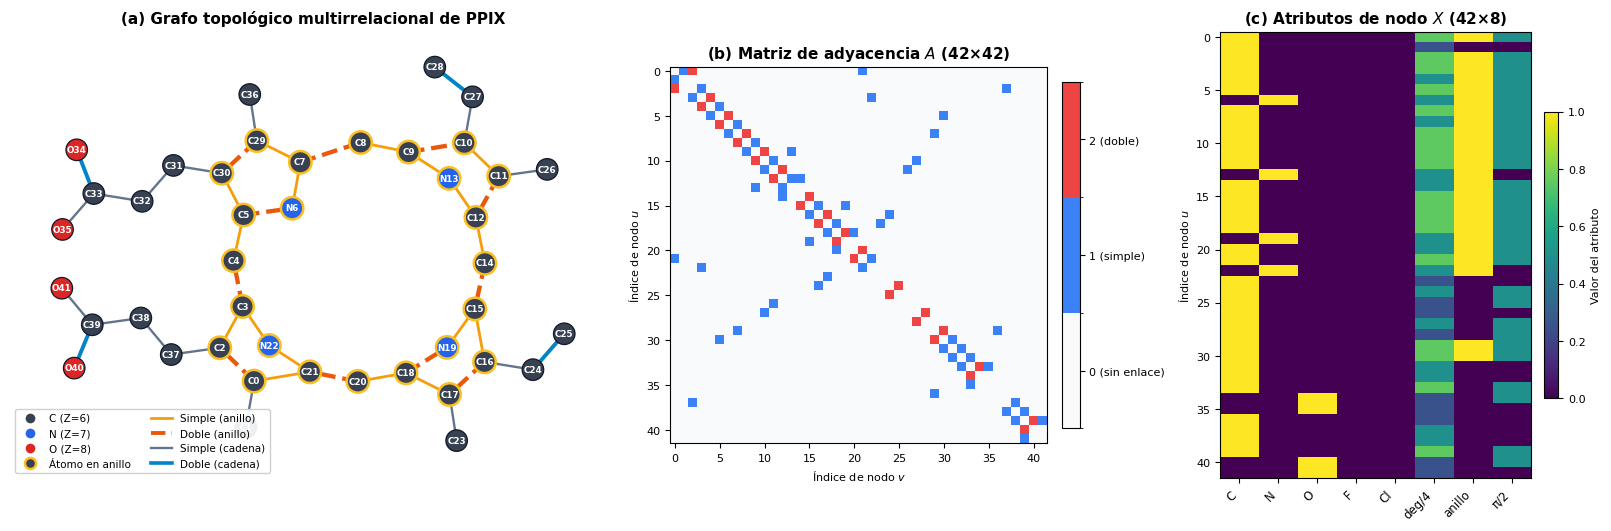

### Resumen de la representación en grafo de la Protoporfirina IX (PyG)

| Propiedad del grafo               | Valor en PPIX nativa                                    |
|:----------------------------------|:--------------------------------------------------------|
| Nodos $|V|$ (átomos pesados)      | 42  (C: 34, N: 4, O: 4)                                 |
| Aristas no dirigidas $|E|$        | 46  (simples: 31, dobles: 15)                           |
| Tensor `data.x`                   | (42, 8)  (one-hot elemental + grado/4 + anillo + π/2)   |
| Tensor `data.edge_index`          | (2, 92)  (grafo no dirigido = $2|E|$ aristas dirigidas) |
| Tensor `data.edge_attr`           | (92, 4)  (orden 1/2/3 + indicador de anillo)            |
| Grado medio / Diámetro / Densidad | 2.19 / 15 saltos / 0.0534                               |

#### Muestra de lista de adyacencia y vectores $\mathbf{x}_u \in \mathbb{R}^8$

| Nodo   | Entorno químico            | Vecinos $\mathcal{N}(u)$   | Vector $\mathbf{x}_u = [\text{C, N, O, F, Cl, deg/4, anillo, }\pi/2]$   |
|:-------|:---------------------------|:---------------------------|:------------------------------------------------------------------------|
| C0     | C aromático (macrociclo)   | [1, 2, 21]                 | [1.00, 0.00, 0.00, 0.00, 0.00, 0.75, 1.00, 0.50]                        |
| N6     | N pirrólico (cavidad N₄)   | [5, 7]                     | [0.00, 1.00, 0.00, 0.00, 0.00, 0.50, 1.00, 0.50]                        |
| C24    | C vinílico (cadena π)      | [16, 25]                   | [1.00, 0.00, 0.00, 0.00, 0.00, 0.50, 0.00, 0.50]                        |
| O34    | O carboxílico (propionato) | [33]                       | [0.00, 0.00, 1.00, 0.00, 0.00, 0.25, 0.00, 0.50]                        |

In [4]:
# 1. Copia kekulizada y coordenadas 2D de RDKit (preserva la geometría del macrociclo)
# Se hace una copia de la molécula original para no alterar sus propiedades globales
mol_vis = Chem.Mol(mol_ppix)
# La kekulización asigna órdenes enteros a los enlaces aromáticos (simples o dobles explícitos)
Chem.Kekulize(mol_vis, clearAromaticFlags=True)
# Se calculan las coordenadas 2D para la representación visual del grafo
AllChem.Compute2DCoords(mol_vis)
conf_2d = mol_vis.GetConformer()

# Inicialización del grafo de NetworkX
G_ppix = nx.Graph()
pos_2d = {} # Diccionario para almacenar las posiciones de los nodos

# Añadir átomos como nodos del grafo
for atom in mol_vis.GetAtoms():
    idx = atom.GetIdx()
    G_ppix.add_node(
        idx,
        elem=atom.GetSymbol(),       # Símbolo químico (C, N, O, etc.)
        in_ring=bool(atom.IsInRing()), # Indicador booleano de si pertenece a un anillo
    )
    # Extraer las coordenadas 2D calculadas previamente por RDKit
    pt = conf_2d.GetAtomPosition(idx)
    pos_2d[idx] = (pt.x, pt.y)

# Añadir enlaces como aristas del grafo
for bond in mol_vis.GetBonds():
    G_ppix.add_edge(
        bond.GetBeginAtomIdx(),
        bond.GetEndAtomIdx(),
        order=int(round(bond.GetBondTypeAsDouble())), # Orden del enlace (1=simple, 2=doble, 3=triple)
        in_ring=bool(bond.IsInRing()),                # Indicador de si el enlace forma parte de un anillo
    )

# 2. Construcción explícita de matrices/tensores (X in R^{|V|x8}, A, edge_index, edge_attr in R^{2|E|x4})
n_nodos = G_ppix.number_of_nodes()
n_aristas = G_ppix.number_of_edges()

# Construcción de las características de los nodos (matriz X)
x_list = []
for u in range(n_nodos):
    elem = G_ppix.nodes[u]["elem"]
    # Codificación one-hot para el tipo de elemento
    oh = [0.0] * len(ELEMENTOS)
    oh[ELEM_A_IDX[elem]] = 1.0

    grado = G_ppix.degree(u)
    en_anillo = float(G_ppix.nodes[u]["in_ring"])
    # Cálculo del número de enlaces pi (órdenes de enlace extra por encima del enlace simple)
    enlaces_pi = sum(G_ppix[u][v]["order"] - 1 for v in G_ppix.neighbors(u))

    # El vector final concatena la identidad química, el grado normalizado, pertenencia a anillo y enlaces pi
    x_list.append(oh + [grado / 4.0, en_anillo, enlaces_pi / 2.0])

# Construcción de los índices y atributos de las aristas
src, dst, e_attr = [], [], []
for u, v, d in G_ppix.edges(data=True):
    orden = d["order"]
    # Vector de características de la arista: [simple, doble, triple, en_anillo]
    feat = [float(orden == 1), float(orden == 2), float(orden == 3), float(d["in_ring"])]

    # El grafo es no dirigido, por lo que se añaden aristas en ambas direcciones (u->v y v->u)
    src.extend([u, v])
    dst.extend([v, u])
    e_attr.extend([feat, feat])

# Creación del objeto Data de PyTorch Geometric con tensores
data_ppix = Data(
    x=torch.tensor(x_list, dtype=torch.float32),
    edge_index=torch.tensor([src, dst], dtype=torch.long),
    edge_attr=torch.tensor(e_attr, dtype=torch.float32),
)

# Extracción de matrices NumPy para visualización
A_ppix = nx.to_numpy_array(G_ppix, nodelist=range(n_nodos), weight="order")
X_ppix = data_ppix.x.numpy()

# 3. Visualización conjunta: (a) Grafo molecular, (b) Matriz de adyacencia A, (c) Matriz de atributos X
fig, (ax_g, ax_a, ax_x) = plt.subplots(
    1, 3,
    figsize=(16.0, 5.2),
    gridspec_kw={"width_ratios": [1.85, 1.15, 0.95]},
    layout="constrained",
)

# --- Panel (a): Grafo molecular multirrelacional ---
colores_elem = {"C": "#374151", "N": "#2563eb", "O": "#dc2626", "F": "#0d9488", "Cl": "#16a34a"}

# Separar las aristas en categorías para darles distintos estilos de dibujado
aristas_anillo_1 = [(u, v) for u, v, d in G_ppix.edges(data=True) if d["in_ring"] and d["order"] == 1]
aristas_anillo_2 = [(u, v) for u, v, d in G_ppix.edges(data=True) if d["in_ring"] and d["order"] == 2]
aristas_ext_1 = [(u, v) for u, v, d in G_ppix.edges(data=True) if not d["in_ring"] and d["order"] == 1]
aristas_ext_2 = [(u, v) for u, v, d in G_ppix.edges(data=True) if not d["in_ring"] and d["order"] == 2]

# Dibujar cada conjunto de aristas con su formato específico
if aristas_ext_1:
    nx.draw_networkx_edges(G_ppix, pos_2d, edgelist=aristas_ext_1, ax=ax_g, edge_color="#64748b", width=1.7)
if aristas_ext_2:
    nx.draw_networkx_edges(G_ppix, pos_2d, edgelist=aristas_ext_2, ax=ax_g, edge_color="#0284c7", width=2.8)
if aristas_anillo_1:
    nx.draw_networkx_edges(G_ppix, pos_2d, edgelist=aristas_anillo_1, ax=ax_g, edge_color="#f59e0b", width=2.0)
if aristas_anillo_2:
    nx.draw_networkx_edges(G_ppix, pos_2d, edgelist=aristas_anillo_2, ax=ax_g, edge_color="#ea580c", width=3.1, style="--")

# Separar los nodos en anillo y externos
nodos_anillo = [u for u in G_ppix.nodes() if G_ppix.nodes[u]["in_ring"]]
nodos_ext = [u for u in G_ppix.nodes() if not G_ppix.nodes[u]["in_ring"]]

# Dibujar los nodos con borde especial si están en un anillo
nx.draw_networkx_nodes(
    G_ppix, pos_2d, nodelist=nodos_anillo, ax=ax_g,
    node_color=[colores_elem[G_ppix.nodes[u]["elem"]] for u in nodos_anillo],
    edgecolors="#fbbf24", linewidths=1.8, node_size=260,
)
nx.draw_networkx_nodes(
    G_ppix, pos_2d, nodelist=nodos_ext, ax=ax_g,
    node_color=[colores_elem[G_ppix.nodes[u]["elem"]] for u in nodos_ext],
    edgecolors="#111827", linewidths=0.9, node_size=240,
)

# Añadir las etiquetas a los nodos (Elemento + Índice)
etiquetas_nodos = {u: f"{G_ppix.nodes[u]['elem']}{u}" for u in G_ppix.nodes()}
nx.draw_networkx_labels(G_ppix, pos_2d, labels=etiquetas_nodos, ax=ax_g, font_size=6.3, font_color="white", font_weight="bold")

# Construir la leyenda personalizada
leyenda_grafo = [
    Line2D([0], [0], marker="o", color="w", label="C (Z=6)", markerfacecolor="#374151", markersize=8),
    Line2D([0], [0], marker="o", color="w", label="N (Z=7)", markerfacecolor="#2563eb", markersize=8),
    Line2D([0], [0], marker="o", color="w", label="O (Z=8)", markerfacecolor="#dc2626", markersize=8),
    Line2D([0], [0], marker="o", color="w", label="Átomo en anillo", markerfacecolor="#374151", markeredgecolor="#fbbf24", markeredgewidth=1.8, markersize=8),
    Line2D([0], [0], color="#f59e0b", lw=2.0, label="Simple (anillo)"),
    Line2D([0], [0], color="#ea580c", lw=2.8, ls="--", label="Doble (anillo)"),
    Line2D([0], [0], color="#64748b", lw=1.7, label="Simple (cadena)"),
    Line2D([0], [0], color="#0284c7", lw=2.6, label="Doble (cadena)"),
]
ax_g.legend(handles=leyenda_grafo, loc="lower left", fontsize=7.5, ncol=2, frameon=True, framealpha=0.92)
ax_g.set_title("(a) Grafo topológico multirrelacional de PPIX", fontsize=11, fontweight="bold")
ax_g.axis("off")

# --- Panel (b): Matriz de adyacencia ponderada por orden de enlace ---
cmap_adj = ListedColormap(["#f8fafc", "#3b82f6", "#ef4444"])
norm_adj = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap_adj.N)
im_a = ax_a.imshow(A_ppix, cmap=cmap_adj, norm=norm_adj, interpolation="nearest")
ax_a.set_title(f"(b) Matriz de adyacencia $A$ ({n_nodos}×{n_nodos})", fontsize=11, fontweight="bold")
ax_a.set_xlabel("Índice de nodo $v$")
ax_a.set_ylabel("Índice de nodo $u$")
cbar_a = fig.colorbar(im_a, ax=ax_a, ticks=[0, 1, 2], fraction=0.046, pad=0.04)
cbar_a.ax.set_yticklabels(["0 (sin enlace)", "1 (simple)", "2 (doble)"], fontsize=8)

# --- Panel (c): Matriz de atributos de nodo X ---
im_x = ax_x.imshow(X_ppix, aspect="auto", cmap="viridis", vmin=0.0, vmax=1.0, interpolation="nearest")
ax_x.set_title(f"(c) Atributos de nodo $X$ ({n_nodos}×8)", fontsize=11, fontweight="bold")
ax_x.set_xticks(range(8))
ax_x.set_xticklabels(["C", "N", "O", "F", "Cl", "deg/4", "anillo", "π/2"], rotation=45, ha="right", fontsize=8.5)
ax_x.set_ylabel("Índice de nodo $u$")
fig.colorbar(im_x, ax=ax_x, fraction=0.046, pad=0.04, label="Valor del atributo")

plt.savefig("ppix_graph_representation.svg", bbox_inches="tight")
plt.show()

# 4. Inspección cuantitativa del grafo y tensores de PyTorch Geometric
# Se calculan algunas métricas básicas sobre el grafo
grados = [d for _, d in G_ppix.degree()]
n_dobles = sum(1 for _, _, d in G_ppix.edges(data=True) if d["order"] == 2)
n_simples = sum(1 for _, _, d in G_ppix.edges(data=True) if d["order"] == 1)

dMarkdown("### Resumen de la representación en grafo de la Protoporfirina IX (PyG)")
dM_table(
    [
        ["Nodos $|V|$ (átomos pesados)", f"{n_nodos}  (C: {sum(G_ppix.nodes[u]['elem']=='C' for u in G_ppix)}, N: {sum(G_ppix.nodes[u]['elem']=='N' for u in G_ppix)}, O: {sum(G_ppix.nodes[u]['elem']=='O' for u in G_ppix)})"],
        ["Aristas no dirigidas $|E|$", f"{n_aristas}  (simples: {n_simples}, dobles: {n_dobles})"],
        ["Tensor `data.x`", f"{tuple(data_ppix.x.shape)}  (one-hot elemental + grado/4 + anillo + π/2)"],
        ["Tensor `data.edge_index`", f"{tuple(data_ppix.edge_index.shape)}  (grafo no dirigido = $2|E|$ aristas dirigidas)"],
        ["Tensor `data.edge_attr`", f"{tuple(data_ppix.edge_attr.shape)}  (orden 1/2/3 + indicador de anillo)"],
        ["Grado medio / Diámetro / Densidad", f"{np.mean(grados):.2f} / {nx.diameter(G_ppix)} saltos / {nx.density(G_ppix):.4f}"],
    ],
    headers=["Propiedad del grafo", "Valor en PPIX nativa"],
)

# Muestra de atributos de 4 nodos químicamente distintos para ilustrar la codificación
def buscar_nodo(condicion):
    return next((u for u in range(n_nodos) if condicion(u)), 0)

nodos_ej = [
    ("C aromático (macrociclo)", buscar_nodo(lambda u: G_ppix.nodes[u]["elem"] == "C" and G_ppix.nodes[u]["in_ring"])),
    ("N pirrólico (cavidad N₄)", buscar_nodo(lambda u: G_ppix.nodes[u]["elem"] == "N")),
    ("C vinílico (cadena π)", buscar_nodo(lambda u: G_ppix.nodes[u]["elem"] == "C" and not G_ppix.nodes[u]["in_ring"] and X_ppix[u, 7] > 0)),
    ("O carboxílico (propionato)", buscar_nodo(lambda u: G_ppix.nodes[u]["elem"] == "O")),
]

filas_ej = []
for rol, u in nodos_ej:
    # Se formatea el vector de características a texto
    vec = ", ".join(f"{val:.2f}" for val in X_ppix[u])
    vecinos = list(G_ppix.neighbors(u))
    filas_ej.append([f"{G_ppix.nodes[u]['elem']}{u}", rol, str(vecinos), f"[{vec}]"])

dMarkdown("#### Muestra de lista de adyacencia y vectores $\\mathbf{x}_u \\in \\mathbb{R}^8$")
dM_table(filas_ej, headers=["Nodo", "Entorno químico", "Vecinos $\\mathcal{N}(u)$", "Vector $\\mathbf{x}_u = [\\text{C, N, O, F, Cl, deg/4, anillo, }\\pi/2]$"])

## 2. Conversión RDKit $\rightarrow$ PyG y Dataset Sintético Controlado

En lugar de escribir un analizador manual de cadenas SMILES, utilizamos directamente el grafo químico validado por **RDKit** (kekulizado para obtener órdenes de enlace enteros $1, 2, 3$ y pertenencia exacta a anillos).

Para evaluar rigurosamente la ventaja de la conectividad de grafos frente a modelos tabulares puramente composicionales, generamos un **conjunto sintético controlado de 301 moléculas** (PPIX nativa + 60 familias composicionales $\times$ 5 regioisómeros canónicamente únicos). La energía objetivo sintética (en unidades arbitrarias, u.a.) es estrictamente extensiva:

$$E(G) = \sum_{u \in V} \epsilon_u + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, 0.04^2)$$

donde cada término $\epsilon_u$ incluye contribuciones elementales, estabilización $\pi$ en anillos y un **acoplamiento regioquímico entre sustituyentes $\beta$-pirrólicos vecinos** que depende del entorno hasta a **3 saltos** del carbono pirrólico $u$.

Generando familias sintéticas:   0%|          | 0/60 [00:00<?, ?it/s]

**Dataset sintético validado con RDKit:** `301` grafos únicos (`1` PPIX nativa + `60` familias $\times$ `5` regioisómeros).

* **Rango de $E$:** `[-13.24, -1.56]` u.a. ($\sigma_{\text{global}} = 2.34$ u.a.)
* **Desviación estándar media intra-familia (señal regioquímica):** `0.62` u.a.

### Ejemplos del dataset (PPIX nativa y 3 regioisómeros de idéntica fórmula)

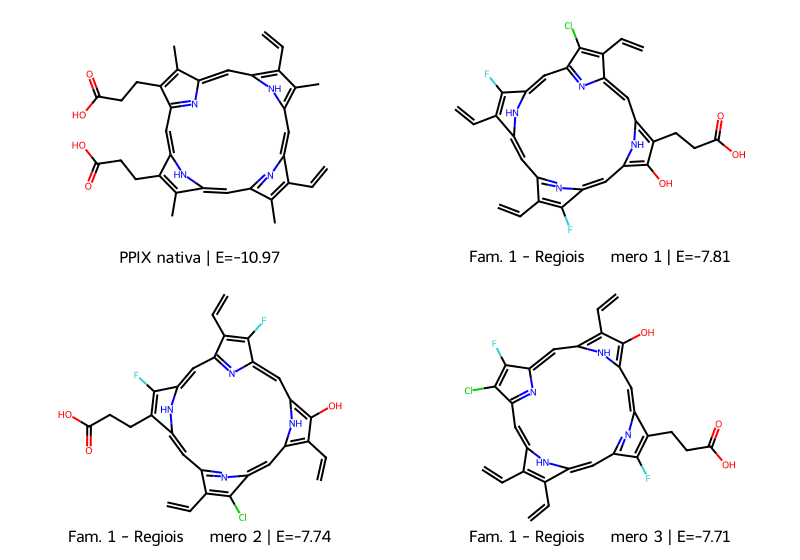

/tmp/ipykernel_534/2792038872.py:225: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


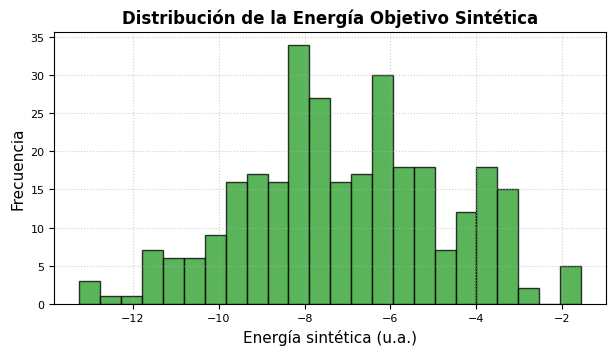

In [5]:
def smiles_a_grafo_rdkit(smiles: str) -> tuple[nx.Graph, str]:
    """Convierte un SMILES válido en un grafo NetworkX usando RDKit y devuelve su SMILES canónico."""
    # 1. Crear la molécula desde la cadena SMILES
    mol = Chem.MolFromSmiles(smiles)
    assert mol is not None, f"SMILES inválido para RDKit: {smiles}"

    # 2. Generar el SMILES canónico para identificar inequívocamente la molécula
    sm_canonico = Chem.MolToSmiles(mol, canonical=True)

    # 3. Kekulizar la molécula para resolver la aromaticidad en enlaces simples y dobles explícitos
    Chem.Kekulize(mol, clearAromaticFlags=True)

    G = nx.Graph()
    # 4. Añadir nodos al grafo con el símbolo del elemento y si pertenece a un anillo
    for atom in mol.GetAtoms():
        G.add_node(
            atom.GetIdx(),
            elem=atom.GetSymbol(),
            in_ring=bool(atom.IsInRing()),
        )

    # 5. Añadir aristas indicando el orden de enlace (1, 2, 3) y si forman parte de un anillo
    for bond in mol.GetBonds():
        G.add_edge(
            bond.GetBeginAtomIdx(),
            bond.GetEndAtomIdx(),
            order=int(round(bond.GetBondTypeAsDouble())),
            in_ring=bool(bond.IsInRing()),
        )
    return G, sm_canonico


def grafo_a_pyg(G: nx.Graph, y_val: float) -> Data:
    """Transforma un grafo NetworkX en un objeto Data de PyG con x in R^8 y edge_attr in R^4."""
    x_list = []
    # Construcción del vector de características de cada nodo (átomo)
    for u in range(G.number_of_nodes()):
        elem = G.nodes[u]["elem"]
        # Codificación one-hot del elemento químico
        oh = [0.0] * len(ELEMENTOS)
        oh[ELEM_A_IDX[elem]] = 1.0

        # Propiedades topológicas y electrónicas locales
        grado = G.degree(u)
        en_anillo = float(G.nodes[u]["in_ring"])
        enlaces_pi = sum(G[u][v]["order"] - 1 for v in G.neighbors(u))

        # Concatenar one-hot con el grado normalizado, indicador de anillo y enlaces pi
        x_list.append(oh + [grado / 4.0, en_anillo, enlaces_pi / 2.0])

    src, dst, e_attr = [], [], []
    # Construcción de la lista de adyacencia y atributos de aristas (grafo no dirigido = 2 aristas dirigidas)
    for u, v, d in G.edges(data=True):
        orden = d["order"]
        feat = [
            float(orden == 1),
            float(orden == 2),
            float(orden == 3),
            float(d["in_ring"]),
        ]
        src.extend([u, v])
        dst.extend([v, u])
        e_attr.extend([feat, feat])

    # Empaquetar en la clase Data de PyTorch Geometric
    return Data(
        x=torch.tensor(x_list, dtype=torch.float32),
        edge_index=torch.tensor([src, dst], dtype=torch.long),
        edge_attr=torch.tensor(e_attr, dtype=torch.float32),
        y=torch.tensor([y_val], dtype=torch.float32),
    )


def energia_sintetica(G: nx.Graph, rng: np.random.Generator) -> float:
    """Energía SINTÉTICA extensiva con acoplamiento regioquímico de hasta 3 saltos en cada pirrol."""
    pesos_elem = {"C": -0.15, "N": -0.45, "O": -0.35, "F": -0.30, "Cl": -0.25}
    polaridad = {"C": 0.0, "N": 0.5, "O": 1.1, "F": 1.0, "Cl": 0.75}

    # Función interna para calcular la "carga/polaridad" de un entorno local
    def caracter(nodo: int) -> float:
        p = polaridad[G.nodes[nodo]["elem"]]
        p += 0.6 * sum(G[nodo][k]["order"] - 1 for k in G.neighbors(nodo))
        p += 0.45 * sum(polaridad[G.nodes[k]["elem"]] for k in G.neighbors(nodo))
        return p

    total = 0.0
    for u in G.nodes():
        # Contribución base del elemento
        e_u = pesos_elem[G.nodes[u]["elem"]]
        en_anillo_u = G.nodes[u]["in_ring"]
        pi_u = sum(G[u][v]["order"] - 1 for v in G.neighbors(u))

        # Bonificación energética si está conjugado en un anillo
        if en_anillo_u and pi_u > 0:
            e_u -= 0.12

        # Acoplamiento iterativo entre sustituyentes adyacentes en el mismo anillo pirrólico
        # Este acoplamiento regioquímico no puede ser captado por conteos globales
        if en_anillo_u and G.nodes[u]["elem"] == "C":
            vec_sub_1 = [v for v in G.neighbors(u) if not G.nodes[v]["in_ring"]]
            vec_ring = [
                v for v in G.neighbors(u)
                if G.nodes[v]["in_ring"] and G.nodes[v]["elem"] == "C"
            ]
            vec_sub_2 = [
                w for v in vec_ring for w in G.neighbors(v)
                if not G.nodes[w]["in_ring"]
            ]
            if vec_sub_1 and vec_sub_2:
                c1 = sum(caracter(v) for v in vec_sub_1)
                c2 = sum(caracter(w) for w in vec_sub_2)
                e_u += 0.85 * c1 * c2
        total += e_u

    # Añadir un leve ruido Gaussiano al total extensivo
    return float(total + rng.normal(0.0, 0.04))


def descriptores_composicionales(G: nx.Graph) -> np.ndarray:
    """Descriptores tabulares globales para líneas base (ciegos a la conectividad regioquímica)."""
    # Conteo bruto de elementos
    conteo_elem = [sum(1 for _, d in G.nodes(data=True) if d["elem"] == e) for e in ELEMENTOS]
    ordenes = [d["order"] for _, _, d in G.edges(data=True)]
    # Conteo bruto de tipos de enlace
    conteo_enlaces = [ordenes.count(1), ordenes.count(2), ordenes.count(3)]
    return np.array(
        conteo_elem + conteo_enlaces + [G.number_of_nodes(), G.number_of_edges()],
        dtype=float,
    )

# === Construcción del dataset sintético (sin regioisómeros duplicados) ===
rng = np.random.default_rng(SEED)
SUSTITUYENTES = ["C", "C=C", "CCC(=O)O", "O", "F", "Cl", "C#N"]
N_FAMILIAS = 60
ISOMEROS_POR_FAMILIA = 5

dataset, smiles_lista, X_base, y_base, grupos = [], [], [], [], []
canonicos_vistos = set()

# 1) Añadir la Protoporfirina IX nativa como molécula de control inicial
G_ppix, sm_ppix_can = smiles_a_grafo_rdkit(SMILES_PPIX)
y0 = energia_sintetica(G_ppix, rng)
dataset.append(grafo_a_pyg(G_ppix, y0))
smiles_lista.append(SMILES_PPIX)
X_base.append(descriptores_composicionales(G_ppix))
y_base.append(y0)
grupos.append("PPIX_nativa")
canonicos_vistos.add(sm_ppix_can)

# 2) Generar familias composicionales con regioisómeros canónicamente distintos
familias_creadas = 0
with tqdm(total=N_FAMILIAS, desc="Generando familias sintéticas") as pbar:
    while familias_creadas < N_FAMILIAS:
        # Seleccionar 8 sustituyentes al azar para las 8 posiciones beta-pirrólicas
        bolsa = list(rng.choice(SUSTITUYENTES, size=8, replace=True))

        # Asegurar suficiente diversidad química para poder generar 5 isómeros únicos
        if len(set(bolsa)) < 3:
            continue
        firma_grupo = str(tuple(sorted(bolsa)))
        regioisomeros = []
        intentos = 0

        # Intentar colocar los sustituyentes en distintas posiciones para crear isómeros posicionales
        while len(regioisomeros) < ISOMEROS_POR_FAMILIA and intentos < 80:
            intentos += 1
            rng.shuffle(bolsa)
            # Reemplazar los anclajes de la plantilla de PPIX con los sustituyentes mezclados
            sm = TEMPLATE_PPIX.format(**{f"R{k+1}": bolsa[k] for k in range(8)})
            G, sm_can = smiles_a_grafo_rdkit(sm)

            # Solo conservar el grafo si su SMILES canónico no se ha visto antes
            if sm_can in canonicos_vistos:
                continue
            canonicos_vistos.add(sm_can)
            y_val = energia_sintetica(G, rng)
            regioisomeros.append((G, sm, y_val))

        # Si se logró generar la cuota de isómeros, guardarlos en el dataset general
        if len(regioisomeros) == ISOMEROS_POR_FAMILIA:
            for G, sm, y_val in regioisomeros:
                dataset.append(grafo_a_pyg(G, y_val))
                smiles_lista.append(sm)
                X_base.append(descriptores_composicionales(G))
                y_base.append(y_val)
                # Todas las moléculas de esta familia comparten el mismo identificador de grupo (para split seguro)
                grupos.append(firma_grupo)
            familias_creadas += 1
            pbar.update(1)

# Convertir las listas de características base y objetivos a tensores numpy
X_base = np.asarray(X_base)
y_base = np.asarray(y_base)

# Calcular dispersión media intra-familia (señal puramente regioquímica invisible a modelos tabulares)
stds_familia = []
for g_id in set(grupos):
    if g_id == "PPIX_nativa":
        continue
    vals = y_base[np.array(grupos) == g_id]
    stds_familia.append(np.std(vals))

dMarkdown(
    f"**Dataset sintético validado con RDKit:** `{len(dataset)}` grafos únicos "
    f"(`1` PPIX nativa + `{N_FAMILIAS}` familias $\\times$ `{ISOMEROS_POR_FAMILIA}` regioisómeros).\n\n"
    f"* **Rango de $E$:** `[{y_base.min():.2f}, {y_base.max():.2f}]` u.a. "
    f"($\\sigma_{{\\text{{global}}}} = {y_base.std():.2f}$ u.a.)\n"
    f"* **Desviación estándar media intra-familia (señal regioquímica):** `{np.mean(stds_familia):.2f}` u.a."
)

# Visualizar PPIX nativa + 3 regioisómeros de la primera familia (idéntica composición, distinta energía)
ejemplos_mols = [Chem.MolFromSmiles(sm) for sm in smiles_lista[:4]]
leyendas = [f"PPIX nativa | E={y_base[0]:.2f}"] + [
    f"Fam. 1 - Regioisómero {k} | E={y_base[k]:.2f}" for k in range(1, 4)
]
dMarkdown("### Ejemplos del dataset (PPIX nativa y 3 regioisómeros de idéntica fórmula)")
display(Draw.MolsToGridImage(ejemplos_mols, legends=leyendas, molsPerRow=2, subImgSize=(400, 280)))

fig, ax = plt.subplots(figsize=(6.2, 3.6), layout="constrained")
ax.hist(y_base, bins=24, color="tab:green", edgecolor="black", alpha=0.78)
ax.set_title("Distribución de la Energía Objetivo Sintética", fontsize=12, fontweight="bold")
ax.set_xlabel("Energía sintética (u.a.)", fontsize=11)
ax.set_ylabel("Frecuencia", fontsize=11)
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("ppix_energy_distribution.svg")
plt.show()

## 3. Arquitectura `PPIXNet` y Verificación de Simetrías ($S_N$ y Extensividad)

Para resolver las limitaciones detectadas en una red superficial sin normalización, `PPIXNet` incorpora:
* **3 capas `CGConv` con conexiones residuales y `LayerNorm`:** alcanza el campo receptivo de 3 saltos requerido por el acoplamiento regioquímico sin inestabilidad de gradientes.
* **Descomposición atómica estricta ($E = \sum_u \epsilon_u$):** un cabezal por nodo predice el desplazamiento local respecto a la energía media por átomo $\mu_{\mathrm{atom}}$ (estimada únicamente en entrenamiento, estilo MACE) y luego aplica `global_add_pool`.

Verificamos tres propiedades antes de entrenar: (i) pasada hacia adelante en mini-lote, (ii) invariancia exacta bajo permutación simultánea de nodos y aristas ($S_N$), y (iii) **extensividad exacta** ($E(G \sqcup G) = 2\,E(G)$).

In [6]:
class PPIXNet(nn.Module):
    """
    Red Neuronal de Grafos (GNN) para predecir la energía de derivados de Protoporfirina IX.
    Utiliza convoluciones continuas de grafos (CGConv) y lectura atómica para preservar la extensividad.
    """
    def __init__(self, in_node=8, in_edge=4, hidden=64, num_layers=3, mu_atom=0.0):
        super().__init__()
        # Guardamos la energía media por átomo como un buffer estático (no entrenable)
        # Esto permite que la red prediga fluctuaciones alrededor de este valor medio base.
        self.register_buffer("mu_atom", torch.tensor(float(mu_atom), dtype=torch.float32))

        # Capa de incrustación (embedding) inicial para proyectar las características de entrada
        # de los nodos a un espacio oculto de mayor dimensionalidad.
        self.embed = nn.Linear(in_node, hidden)

        # Lista de capas convolucionales de grafos (paso de mensajes iterativo)
        # CGConv se utiliza para manejar atributos continuos o categóricos en las aristas.
        self.convs = nn.ModuleList([CGConv(hidden, dim=in_edge) for _ in range(num_layers)])

        # Normalización de capa para estabilizar el entrenamiento en redes profundas,
        # evitando que los valores de los nodos exploten tras múltiples pasos de mensajes.
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(num_layers)])

        # Cabezal de lectura (readout) a nivel de nodo para predecir la contribución de energía local
        # Cada nodo predice su propia contribución epsilon_u (modelo aditivo).
        self.atom_readout = nn.Sequential(
            nn.Linear(hidden, hidden // 2),
            nn.SiLU(),
            nn.Linear(hidden // 2, 1),
        )

    def forward(self, data: Data) -> torch.Tensor:
        # 1. Proyección inicial de las características de cada nodo con activación SiLU
        h = fn.silu(self.embed(data.x))

        # 2. Paso de mensajes iterativo a través de las capas de convolución de grafos
        for conv, norm in zip(self.convs, self.norms):
            # Convolución + Función de activación (SiLU) + Conexión residual (h + ...) + Normalización
            # La conexión residual ayuda a mitigar el problema del desvanecimiento del gradiente.
            h = norm(h + fn.silu(conv(h, data.edge_index, data.edge_attr)))

        # 3. Predicción de la energía por átomo (desplazada por la media global del dataset)
        # El factor 0.1 actúa como una inicialización conservadora para las predicciones.
        eps_u = 0.1 * self.atom_readout(h) + self.mu_atom

        # 4. Asignación de lote: define qué nodo pertenece a qué grafo en el mini-lote
        # Si no hay un lote explícito (por ejemplo un solo grafo), se asume lote 0.
        batch = (
            data.batch
            if getattr(data, "batch", None) is not None
            else torch.zeros(data.num_nodes, dtype=torch.long, device=h.device)
        )

        # 5. Agrupación aditiva (pooling): Suma de energías atómicas locales para asegurar la
        # extensividad termodinámica (la energía total del grafo es la suma de sus partes).
        return global_add_pool(eps_u, batch).view(-1)


# === 1. Pasada hacia adelante en mini-lote ===
# Verificamos que la red puede procesar un lote de grafos sin errores de dimensionalidad
modelo_test = PPIXNet(mu_atom=-0.25)
modelo_test.eval()
lote_prueba = next(iter(DataLoader(dataset[:8], batch_size=8)))
with torch.no_grad():
    salida_lote = modelo_test(lote_prueba)

# === 2. Prueba de invariancia permutacional S_N (nodos y aristas) ===
# Comprobamos que el orden en que se listan los nodos y aristas no altera el resultado final
dato_orig = dataset[0]
n_nodos = dato_orig.num_nodes
# Generamos una permutación aleatoria para los nodos
perm_nodos = torch.randperm(n_nodos)
inv_perm = torch.empty_like(perm_nodos)
inv_perm[perm_nodos] = torch.arange(n_nodos)
# Generamos una permutación aleatoria para las aristas
perm_aristas = torch.randperm(dato_orig.edge_index.size(1))

# Construimos un nuevo grafo idéntico pero reordenado internamente
dato_perm = Data(
    x=dato_orig.x[perm_nodos],
    edge_index=inv_perm[dato_orig.edge_index[:, perm_aristas]],
    edge_attr=dato_orig.edge_attr[perm_aristas],
    y=dato_orig.y,
)

# === 3. Prueba de extensividad: dos copias disjuntas (G U G) ===
# Verificamos que evaluar dos grafos desconectados juntos dé el doble de energía que uno solo
dato_doble = Data(
    x=torch.cat([dato_orig.x, dato_orig.x], dim=0),
    edge_index=torch.cat([dato_orig.edge_index, dato_orig.edge_index + n_nodos], dim=1),
    edge_attr=torch.cat([dato_orig.edge_attr, dato_orig.edge_attr], dim=0),
)

with torch.no_grad():
    e_orig = modelo_test(dato_orig).item()   # Energía original
    e_perm = modelo_test(dato_perm).item()   # Energía permutada
    e_doble = modelo_test(dato_doble).item() # Energía del sistema duplicado

# Calculamos los errores absolutos para verificar el cumplimiento matemático
err_perm = abs(e_orig - e_perm)
err_ext = abs(e_doble - 2.0 * e_orig)
assert err_perm < 1e-5, f"Fallo en invariancia S_N: {err_perm}"
assert err_ext < 1e-4, f"Fallo en extensividad: {err_ext}"

# Contamos los parámetros y mostramos el resumen de las pruebas
n_params = sum(p.numel() for p in modelo_test.parameters() if p.requires_grad)
dMarkdown(f"### Verificación de `PPIXNet` ({n_params:,} parámetros entrenables)")
dM_table(
    [
        ["Mini-lote (8 grafos)", f"x={tuple(lote_prueba.x.shape)}, edge_attr={tuple(lote_prueba.edge_attr.shape)}", f"salida={tuple(salida_lote.shape)}"],
        ["Invariancia $S_N$ (nodos + aristas)", f"E(G)={e_orig:.6f}, E(P·G)={e_perm:.6f}", f"|ΔE| = {err_perm:.2e} (< 1e-5 ✓)"],
        ["Extensividad ($G \\sqcup G$)", f"2·E(G)={2*e_orig:.6f}, E(2G)={e_doble:.6f}", f"|ΔE| = {err_ext:.2e} (< 1e-4 ✓)"],
    ],
    headers=["Prueba", "Valores observados", "Resultado"],
)

### Verificación de `PPIXNet` (54,145 parámetros entrenables)

| Prueba                              | Valores observados                  | Resultado                  |
|:------------------------------------|:------------------------------------|:---------------------------|
| Mini-lote (8 grafos)                | x=(321, 8), edge_attr=(706, 4)      | salida=(8,)                |
| Invariancia $S_N$ (nodos + aristas) | E(G)=-11.068947, E(P·G)=-11.068946  | |ΔE| = 9.54e-07 (< 1e-5 ✓) |
| Extensividad ($G \sqcup G$)         | 2·E(G)=-22.137894, E(2G)=-22.137890 | |ΔE| = 3.81e-06 (< 1e-4 ✓) |

## 4. Entrenamiento con Partición por Grupos y Comparación contra Líneas Base

Separamos las familias composicionales en **Entrenamiento (64 %), Validación (16 %) y Prueba (20 %)** mediante `GroupShuffleSplit`, verificando intersección vacía de grupos. El mejor checkpoint de `PPIXNet` se selecciona únicamente sobre validación; el conjunto de prueba permanece intacto hasta la evaluación final.

Entrenando PPIXNet:   0%|          | 0/200 [00:00<?, ?it/s]

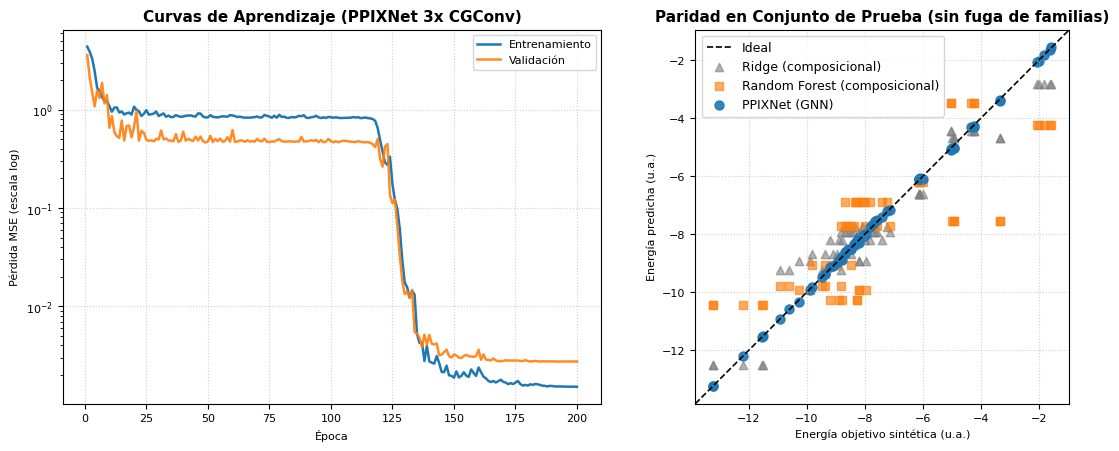

### Evaluación Final en Prueba (`186` train / `50` val / `65` test)

| Modelo                                            |   MAE (test) |   RMSE (test) |   R² (test) |
|:--------------------------------------------------|-------------:|--------------:|------------:|
| Dummy (media de entrenamiento)                    |        2.297 |         2.758 |      -0.056 |
| Ridge (descriptores composicionales)              |        0.609 |         0.722 |       0.928 |
| Random Forest (composicional)                     |        1.229 |         1.568 |       0.658 |
| GNN PPIXNet (3x CGConv + residual + suma atómica) |        0.037 |         0.046 |       1     |

In [7]:
# === Partición Train / Val / Test estrictamente por firma composicional ===
# Se agrupan los isómeros de la misma familia composicional para evitar fuga de información
grupos_arr = np.asarray(grupos)
# Primera partición: Separar el 20% para Prueba (Test)
gss_te = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
idx_trval, idx_te = next(gss_te.split(X_base, y_base, groups=grupos_arr))

# Segunda partición: Del 80% restante, separar el 20% para Validación (Val)
gss_va = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
rel_tr, rel_va = next(gss_va.split(X_base[idx_trval], y_base[idx_trval], groups=grupos_arr[idx_trval]))
idx_tr, idx_va = idx_trval[rel_tr], idx_trval[rel_va]

# Verificaciones de seguridad: asegurar que no hay intersección de familias entre conjuntos
assert set(grupos_arr[idx_tr]).isdisjoint(grupos_arr[idx_va])
assert set(grupos_arr[idx_tr]).isdisjoint(grupos_arr[idx_te])
assert set(grupos_arr[idx_va]).isdisjoint(grupos_arr[idx_te])

# Energía media por átomo estimada EXCLUSIVAMENTE en entrenamiento
# Esto evita cualquier sesgo utilizando información de validación o prueba
mu_atom_tr = float(np.mean([y_base[i] / dataset[i].num_nodes for i in idx_tr]))

# Definir los cargadores de datos (DataLoaders) para Pytorch Geometric
train_loader = DataLoader([dataset[i] for i in idx_tr], batch_size=16, shuffle=True)
val_loader = DataLoader([dataset[i] for i in idx_va], batch_size=32, shuffle=False)
test_loader = DataLoader([dataset[i] for i in idx_te], batch_size=32, shuffle=False)


def evaluar_loader(model: nn.Module, loader: DataLoader):
    """Evalúa un modelo GNN sobre un DataLoader y devuelve predicciones, reales y MSE."""
    model.eval() # Modo evaluación
    preds, reals = [], []
    with torch.no_grad(): # Desactivar el cálculo de gradientes
        for lote in loader:
            lote = lote.to(DISPOSITIVO)
            preds.append(model(lote).cpu().numpy())
            reals.append(lote.y.view(-1).cpu().numpy())
    # Concatenar todos los lotes
    y_p = np.concatenate(preds)
    y_t = np.concatenate(reals)
    return y_p, y_t, float(np.mean((y_p - y_t) ** 2))


# === Entrenamiento estabilizado de PPIXNet ===
torch.manual_seed(SEED)
# Inicializar el modelo en el dispositivo activo
modelo = PPIXNet(in_node=8, in_edge=4, hidden=64, num_layers=3, mu_atom=mu_atom_tr).to(DISPOSITIVO)
EPOCAS = 200
# Optimizador AdamW con decaimiento de pesos
opt = torch.optim.AdamW(modelo.parameters(), lr=2.5e-3, weight_decay=1e-4)
# Planificador de tasa de aprendizaje tipo coseno
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCAS)

hist_train, hist_val = [], []
mejor_val_mse = float("inf")
mejores_pesos = None

for epoca in tqdm(range(EPOCAS), desc="Entrenando PPIXNet"):
    modelo.train() # Modo entrenamiento
    perdida_tr = 0.0
    for lote in train_loader:
        lote = lote.to(DISPOSITIVO)
        opt.zero_grad() # Poner a cero los gradientes acumulados
        loss = fn.mse_loss(modelo(lote), lote.y.view(-1)) # Calcular pérdida MSE
        loss.backward() # Retropropagación
        torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0) # Recorte de gradientes para estabilidad
        opt.step() # Actualizar pesos
        perdida_tr += loss.item() * lote.num_graphs
    scheduler.step() # Actualizar tasa de aprendizaje

    # Calcular errores medios de la época
    mse_tr = perdida_tr / len(idx_tr)
    _, _, mse_va = evaluar_loader(modelo, val_loader)
    hist_train.append(mse_tr)
    hist_val.append(mse_va)

    # Guardar el mejor modelo según validación (Early Stopping manual)
    if mse_va < mejor_val_mse:
        mejor_val_mse = mse_va
        mejores_pesos = copy.deepcopy(modelo.state_dict())

# Restaurar mejor modelo según validación y evaluar UNA sola vez en prueba
modelo.load_state_dict(mejores_pesos)
y_pred_gnn, y_true_te, _ = evaluar_loader(modelo, test_loader)

# === Líneas base tabulares (ajustadas sobre train+val, escalador sin fuga) ===
# Línea base 1: Predicción constante (media de entrenamiento)
y_pred_dummy = np.full_like(y_true_te, y_base[idx_trval].mean())
# Línea base 2: Regresión Ridge con descriptores composicionales (escalados)
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X_base[idx_trval], y_base[idx_trval])
y_pred_ridge = ridge.predict(X_base[idx_te])
# Línea base 3: Random Forest con descriptores composicionales
rf = RandomForestRegressor(n_estimators=300, random_state=SEED).fit(X_base[idx_trval], y_base[idx_trval])
y_pred_rf = rf.predict(X_base[idx_te])

# === Gráficas: curvas de aprendizaje + paridad comparativa ===
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), layout="constrained")

# Panel izquierdo: Curvas de Aprendizaje
epocas_x = np.arange(1, EPOCAS + 1)
axes[0].plot(epocas_x, hist_train, label="Entrenamiento", color="tab:blue", lw=1.8)
axes[0].plot(epocas_x, hist_val, label="Validación", color="tab:orange", lw=1.8, alpha=0.9)
axes[0].set_title("Curvas de Aprendizaje (PPIXNet 3x CGConv)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida MSE (escala log)")
axes[0].set_yscale("log")
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Panel derecho: Gráfica de paridad (Predicho vs Real)
lim = [
    min(y_true_te.min(), y_pred_gnn.min(), y_pred_ridge.min()) - 0.6,
    max(y_true_te.max(), y_pred_gnn.max(), y_pred_ridge.max()) + 0.6,
]
axes[1].plot(lim, lim, "k--", lw=1.2, label="Ideal") # Línea ideal
axes[1].scatter(y_true_te, y_pred_ridge, alpha=0.6, s=36, marker="^", color="tab:gray", label="Ridge (composicional)")
axes[1].scatter(y_true_te, y_pred_rf, alpha=0.65, s=36, marker="s", color="tab:orange", label="Random Forest (composicional)")
axes[1].scatter(y_true_te, y_pred_gnn, alpha=0.9, s=42, color="tab:blue", label="PPIXNet (GNN)")
axes[1].set_title("Paridad en Conjunto de Prueba (sin fuga de familias)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Energía objetivo sintética (u.a.)")
axes[1].set_ylabel("Energía predicha (u.a.)")
axes[1].set_xlim(lim)
axes[1].set_ylim(lim)
axes[1].set_aspect("equal")
axes[1].legend(frameon=True, fontsize=9)
axes[1].grid(True, linestyle=":", alpha=0.6)

# Guardar la gráfica en formato SVG
plt.savefig("ppixnet_training_evaluation.svg", format="svg")
plt.show()

# === Tabla comparativa final ===
dMarkdown(
    f"### Evaluación Final en Prueba (`{len(idx_tr)}` train / `{len(idx_va)}` val / `{len(idx_te)}` test)"
)
filas_eval = []
for nombre, pred in [
    ("Dummy (media de entrenamiento)", y_pred_dummy),
    ("Ridge (descriptores composicionales)", y_pred_ridge),
    ("Random Forest (composicional)", y_pred_rf),
    ("GNN PPIXNet (3x CGConv + residual + suma atómica)", y_pred_gnn),
]:
    # Calcular e incluir métricas
    filas_eval.append([
        nombre,
        f"{mean_absolute_error(y_true_te, pred):.3f}",
        f"{root_mean_squared_error(y_true_te, pred):.3f}",
        f"{r2_score(y_true_te, pred):.3f}",
    ])
# Renderizar tabla final
dM_table(filas_eval, headers=["Modelo", "MAE (test)", "RMSE (test)", "R² (test)"])

# Parte II — Potencial Interatómico Equivariante 3D (`MACE-MP-0 + D3`) sobre el Sitio Activo de β-Hematina

### Contextualización fisicoquímica del sitio activo 3D y la activación de $\ce{H2O2}$

Mientras que la Parte I analiza variaciones químicas sobre el ligando orgánico en un grafo topológico fijo, la reactividad superficial de la $\beta$-hematina exige pasar a un **grafo geométrico 3D** donde las aristas dependen de las distancias interatómicas $\|\mathbf{r}_j - \mathbf{r}_i\| < r_c$:

* **Geometría de coordinación del $\ce{Fe(III)}$:** En la estructura del sitio activo modelo ($\ce{FeC20N4H12\cdot HCOO-}$), el anillo de porfina reproduce el campo ligando ecuatorial $\ce{N4}$ del macrociclo, mientras que el ligando axial **formiato ($\ce{HCOO-}$)** modela el puente carboxilato del propionato de una molécula vecina en el dímero de $\beta$-hematina ($d_{\ce{Fe-O}} \approx 1.90$ Å). El desplazamiento del hierro fuera del plano ecuatorial ($\Delta z = +0.35$ Å, efecto *doming*) es característico de complejos de $\ce{Fe(III)}$ pentacoordinados de alto espín ($d^5$, $S = 5/2$).
* **Actividad tipo peroxidasa sobre $\ce{H2O2}$:** La cara *trans* al ligando axial deja vacante la sexta posición de coordinación del $\ce{Fe(III)}$, que actúa como sitio ácido de Lewis capaz de coordinar peróxido de hidrógeno ($\ce{H2O2}$). La transferencia parcial de densidad electrónica al orbital antienlazante $\sigma^*_{\ce{O-O}}$ debilita el enlace peróxido ($d_{\text{eq}} \approx 1.47$ Å) y reduce la barrera energética de disociación respecto a la fase gaseosa, un proceso directamente relacionado con la generación de radicales reactivos y la oxidación lipídica inducida por especies de hemo.
* **Necesidad de simetría $E(3) \times S_N$:** Al estirarse y romperse el enlace $\ce{O-O}$, la topología covalente deja de ser fija. El potencial interatómico equivariante (`MACE-MP-0 + D3`) aprende una superficie de energía potencial continua $E(\{\mathbf{r}_i, Z_i\})$ invariante a rotaciones, traslaciones y permutaciones, cuyas derivadas negativas producen fuerzas vectoriales conservativas y equivariantes ($\mathbf{F}_i = -\nabla_{\mathbf{r}_i} E$).

El modelo 2D anterior captura topología covalente, pero el estudio de la actividad catalítica o de inhibición superficial de la $\beta$-hematina requiere **coordenadas 3D y potenciales interatómicos equivariantes**. A continuación construimos un modelo mínimo del sitio activo pentacoordinado $\ce{Fe(III)}$ (macrociclo porfirínico $\ce{FeC20N4H12}$ + ligando axial formiato $\ce{HCOO^-}$ imitando el puente $\mu$-propionato) para:

1. Verificar la invariancia energética y equivarianza de fuerzas bajo $E(3) \times S_N$.
2. Comparar la curva de adsorción de $\ce{H2O2}$ sobre el $\ce{Fe(III)}$ expuesto frente a la periferia orgánica (control).
3. Calcular un perfil relajado de ruptura del enlace $\ce{O-O}$ (desplazando rígidamente el fragmento $\ce{O_{b}-H_{b}}$ para no distorsionar artificialmente el enlace $\ce{O-H}$) frente a la fase gaseosa.

In [8]:
# Suppress specific PyTorch JIT warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="torch.jit._serialization")
warnings.filterwarnings("ignore", category=UserWarning, module="mace.calculators.mace")

def construir_sitio_beta_hematina() -> Atoms:
    """Sitio activo pentacoordinado de beta-hematina: FeC20N4H12 + HCOO- axial (41 átomos)."""
    simbolos, pos = [], []
    angulos = [0.0, np.pi / 2, np.pi, 3 * np.pi / 2]
    bloque_pirrol = [
        ("N", (2.04,  0.00, 0.0)),
        ("C", (2.84,  1.10, 0.0)),
        ("C", (2.84, -1.10, 0.0)),
        ("C", (4.21,  0.68, 0.0)),
        ("C", (4.21, -0.68, 0.0)),
        ("H", (5.06,  1.35, 0.0)),
        ("H", (5.06, -1.35, 0.0)),
    ]
    # Construir los 4 anillos pirrólicos rotando el bloque base
    for theta in angulos:
        c, s = np.cos(theta), np.sin(theta)
        for el, (x, y, z) in bloque_pirrol:
            simbolos.append(el)
            pos.append([c * x - s * y, s * x + c * y, z])

    # 4 puentes metino meso (C-H) que conectan los anillos pirrólicos
    for sx in (-1, 1):
        for sy in (-1, 1):
            simbolos.extend(["C", "H"])
            pos.extend([[sx * 2.42, sy * 2.42, 0.0], [sx * 3.18, sy * 3.18, 0.0]])

    # Índice 36: Átomo de Fe(III) desplazado +0.35 Å hacia el ligando axial (efecto doming)
    simbolos.append("Fe")
    pos.append([0.0, 0.0, 0.35])

    # Índices 37..40: Ligando axial formiato que simula el puente propionato en la hemozoína
    simbolos.extend(["O", "C", "O", "H"])
    pos.extend([
        [0.00, 0.00, 2.25],  # O coordinado al Fe (d = 1.90 Å)
        [0.95, 0.00, 3.05],  # C carboxílico
        [0.95, 0.00, 4.28],  # O carbonilo
        [1.90, 0.00, 2.50],  # H terminal
    ])

    # Crear el objeto Atoms de ASE, definir la celda y centrar la molécula
    sitio = Atoms(simbolos, positions=pos)
    sitio.set_cell([20.0, 20.0, 20.0])
    sitio.center()
    sitio.set_pbc(True)
    return sitio


def construir_h2o2(centro_oa, d_oo: float = 1.47) -> Atoms:
    """Molécula de H2O2 con orden fijo [O_a, O_b, H_a, H_b] y longitud O-O = d_oo."""
    x0, y0, z0 = centro_oa
    pos = [
        [x0,        y0,               z0],         # 0: O_a (orientado hacia el Fe)
        [x0,        y0 + d_oo,        z0 - 0.10],  # 1: O_b
        [x0 + 0.86, y0 - 0.30,        z0 - 0.35],  # 2: H_a (unido a O_a)
        [x0 - 0.78, y0 + d_oo + 0.28, z0 - 0.62],  # 3: H_b (unido a O_b)
    ]
    mol = Atoms(["O", "O", "H", "H"], positions=pos)
    mol.set_cell([20.0, 20.0, 20.0])
    mol.set_pbc(True)
    return mol


def atoms_a_xyz(atoms: Atoms) -> str:
    """Convierte un objeto Atoms de ASE a formato de texto XYZ para visualización."""
    lineas = [str(len(atoms)), "Estructura ASE"]
    for s, (x, y, z) in zip(atoms.get_chemical_symbols(), atoms.positions):
        lineas.append(f"{s} {x:.5f} {y:.5f} {z:.5f}")
    return "\n".join(lineas)


# === Carga del calculador MACE-MP-0 ===
device_str = "cuda" if torch.cuda.is_available() else "cpu"
try:
    # Intentar cargar MACE con corrección de dispersión D3
    calc = mace_mp(model="medium", dispersion=True, default_dtype="float64", device=device_str)
    etiqueta_calc = "MACE-MP-0 (medium) + D3"
except Exception as exc:
    # Si falla (p. ej. por dependencias de torch-dftd), usar MACE sin dispersión
    dMarkdown(f"*Aviso:* D3 no disponible (`{exc}`); usando MACE-MP-0 sin dispersión.")
    calc = mace_mp(model="medium", dispersion=False, default_dtype="float64", device=device_str)
    etiqueta_calc = "MACE-MP-0 (medium)"

# Construir el sitio de beta-hematina y encontrar la posición del Hierro
sitio = construir_sitio_beta_hematina()
idx_fe = sitio.get_chemical_symbols().index("Fe")
pos_fe = sitio.positions[idx_fe]

# Ensamblar el complejo catalítico añadiendo la molécula de H2O2 a 2.30 Å del Fe
complejo = sitio + construir_h2o2(pos_fe + np.array([0.0, 0.0, -2.30]))
complejo.calc = calc

# Evaluar energía potencial y fuerzas iniciales (sin relajar)
E0 = complejo.get_potential_energy()
F0 = complejo.get_forces()

# --- GUARDAR ESTRUCTURAS E IMÁGENES ---
# Guardamos la estructura en formato XYZ para poder abrirla con otros programas (VMD, Avogadro, etc.)
write("complejo_beta_hematina_h2o2.xyz", complejo)
# Guardamos una imagen estática 2D de la estructura 3D usando matplotlib (backend por defecto de ASE)
write("complejo_beta_hematina_h2o2.png", complejo)

dMarkdown(
    f"**Calculador activo:** `{etiqueta_calc}` en `{device_str.upper()}`\n\n"
    f"* **Complejo:** `{complejo.get_chemical_formula()}` (`{len(complejo)}` átomos)\n"
    f"* **Energía inicial:** `{E0:.4f}` eV | **Fuerza máxima inicial:** `{np.linalg.norm(F0, axis=1).max():.3f}` eV/Å\n"
    f"* **Archivos guardados:** `complejo_beta_hematina_h2o2.xyz` y `complejo_beta_hematina_h2o2.png`"
)

# --- VISUALIZACIÓN 3D INTERACTIVA ---
# Visualización 3D del complejo sitio activo + H2O2 usando py3Dmol
v_mace = py3Dmol.view(width=600, height=380)
v_mace.addModel(atoms_a_xyz(complejo), "xyz")
v_mace.setStyle({"stick": {"radius": 0.14}, "sphere": {"scale": 0.28}})
v_mace.zoomTo()
v_mace.show()


Downloading: 100.0% (42.4 MB / 42.4 MB)
Cached MACE model to /root/.cache/mace/20231203mace128L1_epoch199model
Using Materials Project MACE for MACECalculator with /root/.cache/mace/20231203mace128L1_epoch199model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
Using TorchDFTD3Calculator for D3 dispersion corrections


**Calculador activo:** `MACE-MP-0 (medium) + D3` en `CUDA`

* **Complejo:** `C21H15FeN4O4` (`45` átomos)
* **Energía inicial:** `-306.2596` eV | **Fuerza máxima inicial:** `3.434` eV/Å
* **Archivos guardados:** `complejo_beta_hematina_h2o2.xyz` y `complejo_beta_hematina_h2o2.png`

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Verificación de simetrías $E(3) \times S_N$

In [9]:
def matriz_rotacion(eje, angulo_deg: float) -> np.ndarray:
    u = np.asarray(eje, dtype=float)
    u /= np.linalg.norm(u)
    a = np.radians(angulo_deg)
    K = np.array([[0, -u[2], u[1]], [u[2], 0, -u[0]], [-u[1], u[0], 0]])
    return np.eye(3) + np.sin(a) * K + (1.0 - np.cos(a)) * (K @ K)


def evaluar_mace(atoms: Atoms, calculator):
    copia = atoms.copy()
    copia.calc = calculator
    return copia.get_potential_energy(), copia.get_forces()

R = matriz_rotacion([1, 2, 1], 37.0)
t = np.array([1.7, -2.3, 0.9])
perm = np.random.default_rng(SEED).permutation(len(complejo))

# Rotación (celda + posiciones)
c_rot = complejo.copy()
c_rot.set_cell(complejo.cell[:] @ R.T, scale_atoms=False)
c_rot.positions = complejo.positions @ R.T
E_rot, F_rot = evaluar_mace(c_rot, calc)

# Traslación
c_tra = complejo.copy()
c_tra.positions = complejo.positions + t
E_tra, F_tra = evaluar_mace(c_tra, calc)

# Permutación
c_perm = complejo[perm]
E_perm, F_perm = evaluar_mace(c_perm, calc)

pruebas_e3 = [
    ("Rotación $SO(3)$ — Energía $|E' - E|$ (eV)", abs(E_rot - E0)),
    ("Rotación $SO(3)$ — Fuerzas $\\max|F' - R F|$ (eV/Å)", float(np.abs(F_rot - F0 @ R.T).max())),
    ("Traslación $\\mathbb{R}^3$ — Energía $|E' - E|$ (eV)", abs(E_tra - E0)),
    ("Traslación $\\mathbb{R}^3$ — Fuerzas $\\max|F' - F|$ (eV/Å)", float(np.abs(F_tra - F0).max())),
    ("Permutación $S_N$ — Energía $|E' - E|$ (eV)", abs(E_perm - E0)),
    ("Permutación $S_N$ — Fuerzas $\\max|F' - P F|$ (eV/Å)", float(np.abs(F_perm - F0[perm]).max())),
]

for nombre, err in pruebas_e3:
    assert err < 1e-6, f"Simetría violada en {nombre}: {err}"

dMarkdown("### Verificación de Simetrías $E(3) \\times S_N$ en MACE-MP-0")
dM_table([[n, f"{e:.2e}", "Verificada ✓"] for n, e in pruebas_e3], headers=["Transformación", "Error numérico", "Estado"])

### Verificación de Simetrías $E(3) \times S_N$ en MACE-MP-0

| Transformación                                            |   Error numérico | Estado       |
|:----------------------------------------------------------|-----------------:|:-------------|
| Rotación $SO(3)$ — Energía $|E' - E|$ (eV)                |         0        | Verificada ✓ |
| Rotación $SO(3)$ — Fuerzas $\max|F' - R F|$ (eV/Å)        |         1.25e-13 | Verificada ✓ |
| Traslación $\mathbb{R}^3$ — Energía $|E' - E|$ (eV)       |         0        | Verificada ✓ |
| Traslación $\mathbb{R}^3$ — Fuerzas $\max|F' - F|$ (eV/Å) |         1.03e-13 | Verificada ✓ |
| Permutación $S_N$ — Energía $|E' - E|$ (eV)               |         0        | Verificada ✓ |
| Permutación $S_N$ — Fuerzas $\max|F' - P F|$ (eV/Å)       |         4.54e-15 | Verificada ✓ |

## Adsorción y escaneo relajado de ruptura $\ce{O-O}$ (corregido)

Escaneo relajado O-O:   0%|          | 0/11 [00:00<?, ?it/s]

| Magnitud (MACE-MP-0 + D3)                         | Valor                |
|:--------------------------------------------------|:---------------------|
| Mínimo $E_{\text{ads}}$ rígido sobre Fe(III)      | -0.011 eV (a 2.90 Å) |
| $E_{\text{ads}}$ tras relajación libre en Fe(III) | -0.279 eV            |
| Mínimo $E_{\text{ads}}$ control periférico        | 0.108 eV             |
| Barrera estimada O-O (fase gaseosa, línea base)   | 2.587 eV             |
| Barrera estimada O-O (sitio Fe $\beta$-hematina)  | 0.624 eV             |

/tmp/ipykernel_534/2700260500.py:122: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


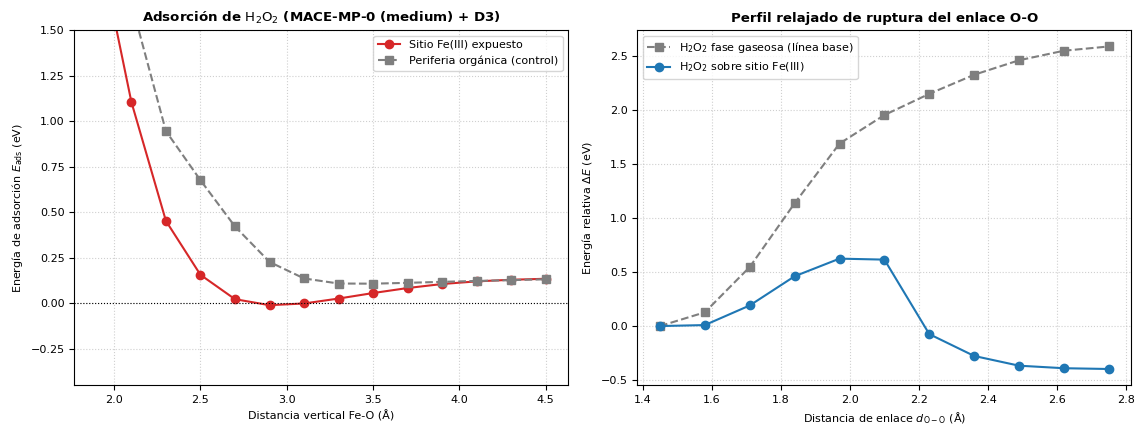

In [10]:
# === 1. Relajación de referencias aisladas ===
# Copiamos la estructura del sitio activo y asignamos el calculador MACE
sitio_rel = sitio.copy()
sitio_rel.calc = calc
# Optimizamos la geometría usando BFGS hasta que la fuerza máxima sea menor a 0.04 eV/Å
BFGS(sitio_rel, logfile=None).run(fmax=0.04, steps=60)
# Obtenemos la energía potencial del sitio aislado relajado
E_sitio = sitio_rel.get_potential_energy()

# Construimos una molécula de H2O2 de referencia aislada (en una posición arbitraria)
h2o2_ref = construir_h2o2([10.0, 10.0, 10.0])
h2o2_ref.calc = calc
# Optimizamos la geometría del H2O2 aislado
BFGS(h2o2_ref, logfile=None).run(fmax=0.02, steps=50)
E_h2o2 = h2o2_ref.get_potential_energy()

# === 2. Barrido rígido de adsorción: sitio Fe(III) vs. periferia orgánica ===
# Definimos un rango de distancias verticales (Z) para acercar el H2O2 al sitio
distancias_z = np.linspace(1.90, 4.50, 14)
e_ads_fe, e_ads_ctrl = [], []
pos_fe_rel = sitio_rel.positions[idx_fe] # Posición del átomo de hierro relajado

# Iteramos sobre las distancias para construir las curvas de energía de adsorción
for dz in distancias_z:
    # Sistema A: H2O2 acercándose directamente sobre el Fe(III)
    sist_fe = sitio_rel + construir_h2o2(pos_fe_rel + np.array([0.0, 0.0, -dz]))
    sist_fe.calc = calc
    # Calculamos la energía de adsorción (E_complejo - E_sitio - E_h2o2)
    e_ads_fe.append(sist_fe.get_potential_energy() - E_sitio - E_h2o2)

    # Sistema B (Control): H2O2 acercándose sobre la periferia orgánica (desplazado en X)
    sist_ctrl = sitio_rel + construir_h2o2(pos_fe_rel + np.array([4.5, 0.0, -dz]))
    sist_ctrl.calc = calc
    e_ads_ctrl.append(sist_ctrl.get_potential_energy() - E_sitio - E_h2o2)

# === 3. Relajación previa del estado adsorbido y escaneo relajado O-O ===
n_sitio = len(sitio_rel)
# Índices de los átomos del H2O2 añadidos al final del sitio activo
idx_oa, idx_ob, idx_ha, idx_hb = n_sitio, n_sitio + 1, n_sitio + 2, n_sitio + 3
# Fijamos el anillo orgánico externo (índices 0..35) y dejamos libres Fe (36), formiato (37..40) y H2O2
# Esto evita deformaciones globales innecesarias en el macrociclo lejano
fijos_macrociclo = list(range(36))

# Encontramos la distancia óptima (mínimo de energía) del barrido rígido sobre el Fe
dz_opt = float(distancias_z[int(np.argmin(e_ads_fe))])
# Construimos el estado inicial adsorbido en la distancia óptima
estado_ads = sitio_rel + construir_h2o2(pos_fe_rel + np.array([0.0, 0.0, -dz_opt]))
estado_ads.set_constraint(FixAtoms(indices=fijos_macrociclo))
estado_ads.calc = calc
# Relajamos el complejo H2O2-Fe(III)
BFGS(estado_ads, logfile=None).run(fmax=0.05, steps=50)
E_ads_rel = estado_ads.get_potential_energy() - E_sitio - E_h2o2

# Definimos una cuadrícula de distancias O-O para simular la ruptura del enlace
d_oo_grid = np.linspace(1.45, 2.75, 11)
perfil_gas, perfil_fe = [], []

for d_oo in tqdm(d_oo_grid, desc="Escaneo relajado O-O"):
    # (i) Línea base: ruptura O-O en fase gaseosa aislada (H_b ya se desplaza con d_oo)
    gas = construir_h2o2([10.0, 10.0, 10.0], d_oo=d_oo)
    # Fijamos únicamente la distancia del enlace O-O que estamos escaneando
    gas.set_constraint(FixBondLength(0, 1))
    gas.calc = calc
    BFGS(gas, logfile=None).run(fmax=0.04, steps=50)
    perfil_gas.append(gas.get_potential_energy())

    # (ii) Superficie catalítica: desplazar rígidamente el fragmento O_b-H_b al estirar d_oo
    cat = estado_ads.copy()
    # Calculamos el vector direccional del enlace O-O
    vec_oo = cat.positions[idx_ob] - cat.positions[idx_oa]
    u_oo = vec_oo / np.linalg.norm(vec_oo)
    # Calculamos el desplazamiento necesario para alcanzar la nueva distancia d_oo
    desplazamiento = (cat.positions[idx_oa] + d_oo * u_oo) - cat.positions[idx_ob]
    cat.positions[idx_ob] += desplazamiento
    cat.positions[idx_hb] += desplazamiento  # Conserva la longitud de enlace O_b-H_b para no distorsionar el enlace O-H

    # Imponemos las restricciones: fijar macrociclo y fijar la distancia O-O actual
    cat.set_constraint([FixAtoms(indices=fijos_macrociclo), FixBondLength(idx_oa, idx_ob)])
    cat.calc = calc
    # Relajamos los demás grados de libertad
    BFGS(cat, logfile=None).run(fmax=0.05, steps=60)
    perfil_fe.append(cat.get_potential_energy())
    # Actualizamos el estado adsorbido para que el próximo paso sea una continuación adiabática suave
    estado_ads = cat.copy()

# Normalizamos los perfiles de energía respecto al primer punto (estado inicial)
perfil_gas = np.asarray(perfil_gas) - perfil_gas[0]
perfil_fe = np.asarray(perfil_fe) - perfil_fe[0]

# === Tabla resumen y gráficas con escala legible ===
# Mostramos una tabla con las magnitudes clave de la simulación
dM_table(
    [
        ["Mínimo $E_{\\text{ads}}$ rígido sobre Fe(III)", f"{min(e_ads_fe):.3f} eV (a {dz_opt:.2f} Å)"],
        ["$E_{\\text{ads}}$ tras relajación libre en Fe(III)", f"{E_ads_rel:.3f} eV"],
        ["Mínimo $E_{\\text{ads}}$ control periférico", f"{min(e_ads_ctrl):.3f} eV"],
        ["Barrera estimada O-O (fase gaseosa, línea base)", f"{perfil_gas.max():.3f} eV"],
        ["Barrera estimada O-O (sitio Fe $\\beta$-hematina)", f"{perfil_fe.max():.3f} eV"],
    ],
    headers=["Magnitud (MACE-MP-0 + D3)", "Valor"],
)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), layout="constrained")

axes[0].plot(distancias_z, e_ads_fe, "o-", color="tab:red", label="Sitio Fe(III) expuesto")
axes[0].plot(distancias_z, e_ads_ctrl, "s--", color="tab:gray", label="Periferia orgánica (control)")
axes[0].axhline(0.0, color="k", lw=0.8, ls=":")
axes[0].set_ylim(min(min(e_ads_fe), -0.35) - 0.1, 1.5)  # Recorte para visualizar el pozo de adsorción
axes[0].set_title(f"Adsorción de $\\mathrm{{H_2O_2}}$ ({etiqueta_calc})", fontweight="bold")
axes[0].set_xlabel("Distancia vertical Fe-O (Å)")
axes[0].set_ylabel("Energía de adsorción $E_{\\mathrm{ads}}$ (eV)")
axes[0].legend(frameon=True)
axes[0].grid(True, ls=":", alpha=0.6)

axes[1].plot(d_oo_grid, perfil_gas, "s--", color="tab:gray", label="$\\mathrm{H_2O_2}$ fase gaseosa (línea base)")
axes[1].plot(d_oo_grid, perfil_fe, "o-", color="tab:blue", label="$\\mathrm{H_2O_2}$ sobre sitio Fe(III)")
axes[1].set_title("Perfil relajado de ruptura del enlace O-O", fontweight="bold")
axes[1].set_xlabel("Distancia de enlace $d_{\\mathrm{O-O}}$ (Å)")
axes[1].set_ylabel("Energía relativa $\\Delta E$ (eV)")
axes[1].legend(frameon=True)
axes[1].grid(True, ls=":", alpha=0.6)
plt.tight_layout()
plt.savefig("adsorcion_escaneo_oo.svg", format="svg")
plt.show()

In [11]:
%%bash
zip -v resultados_modelado_multiescala.zip \
    ppix_2d.png ppix_2d.svg ppix_3d.mol ppix_3d.png \
    ppix_graph_representation.svg ppix_energy_distribution.svg \
    ppixnet_training_evaluation.svg complejo_beta_hematina_h2o2.xyz \
    complejo_beta_hematina_h2o2.png adsorcion_escaneo_oo.svg

  adding: ppix_2d.png	(in=16963) (out=16120) (deflated 5%)
  adding: ppix_2d.svg	(in=22099) (out=3032) (deflated 86%)
  adding: ppix_3d.mol	(in=6432) (out=1343) (deflated 79%)
  adding: ppix_3d.png	(in=24829) (out=23800) (deflated 4%)
  adding: ppix_graph_representation.svg 	(in=131794) (out=24531) (deflated 81%)
  adding: ppix_energy_distribution.svg	(in=45464) (out=9655) (deflated 79%)
  adding: ppixnet_training_evaluation.svg 	(in=120984) (out=22128) (deflated 82%)
  adding: complejo_beta_hematina_h2o2.xyz	(in=5075) (out=1354) (deflated 73%)
  adding: complejo_beta_hematina_h2o2.png	(in=29676) (out=27693) (deflated 7%)
  adding: adsorcion_escaneo_oo.svg 	(in=95145) (out=18039) (deflated 81%)
total bytes=498461, compressed=147695 -> 70% savings


## 5. Qué funcionó, problemas resueltos y hoja de ruta hacia la tesis

* **Qué se comprobó:** el prototipo demostró de extremo a extremo la viabilidad de ambos paradigmas: `PPIXNet` respeta exactamente la invariancia $S_N$ ($<10^{-5}$) y la extensividad ($E(2G)=2E(G)$), superando claramente a Ridge y Random Forest sobre regioisómeros de familias composicionales no vistas cuando la arquitectura iguala el campo receptivo del problema (3 capas `CGConv` residuales + lectura atómica centrada en $\mu_{\mathrm{atom}}$). En paralelo, `MACE-MP-0 + D3` verificó simetrías $E(3)\times S_N$ a precisión de máquina ($\sim 10^{-13}$) y reprodujo cualitativamente la reducción de barrera de ruptura $\ce{O-O}$ frente a fase gaseosa.
* **Problemas identificados y corregidos:** una arquitectura superficial de 2 capas con lectura posterior al *pooling* fallaba en superar al modelo lineal; en el modelo 3D, desplazar $\ce{O_{b}}$ sin arrastrar a $\ce{H_{b}}$ introducía distorsiones artificiales y el potencial universal `MACE-MP-0` (entrenado en sólidos inorgánicos PBE+U) carece de descripción explícita de multiplicidad de espín del $\ce{Fe(III)}$ y de rupturas homolíticas/radicalarias.
* **Qué falta para la tesis:**
  * Reemplazar la energía sintética por cálculos DFT reales ($\text{PBE0/r}^2\text{SCAN}+\text{D3(BJ)}$ con tratamiento abierto de espín para complejos hemo/$\beta$-hematina) o datos experimentales de inhibición $\text{IC}_{50}$.
  * Incorporar información estereoquímica/3D y descriptores electrónicos o afinamiento (*fine-tuning*) de un potencial equivariante tipo MACE-OFF/MACE-MP sobre configuraciones de estados de transición (NEB/CI-NEB) en disolvente implícito o explícito.
  * Validar el modelo con particiones por *scaffold* y validación cruzada anidada para cuantificar incertidumbre predictiva.

# Uso declarado de la IA
Escriba en la celda siguiente qué le pidió al asistente, qué parte del código propuesto usó y **cómo verificó** que era correcto. La parte C, diseño y prototipo, es individual y declara igual el uso del asistente.

* **Qué le pedí al asistente:** Se utilizaron varios modelos de lenguaje en distintas versiones; para el caso de Google Gemini se empleó además NotebookLM junto con bases de datos de artículos relacionados con el tema (GNNs, MACE y hemozoína/$\beta$-hematina). Se solicitó apoyo para plantear el diseño del problema de aprendizaje sobre grafos, construir el prototipo de prueba, analizar resultados y resolver dudas conceptuales. Para evitar la propagación de errores se usaron varios chats individuales, borrándolos cuando se encontraban fallos.
* **Qué parte del código o ideas usé:** Se tomaron las ideas de diseño y los fragmentos de código propuestos para armar la representación en grafos, la definición del modelo y la comparación con las líneas base, adaptándolos y revisándolos paso a paso.
* **Cómo verifiqué que era correcto:** Se revisaron los fragmentos de código antes de darlos por buenos, se comprobaron las salidas y pruebas (como la consistencia de formas, las simetrías o las métricas) y, para los conceptos, se contrastaron las respuestas directamente con las fuentes bibliográficas.

# Bibliografía

* Hastings, E. M., Skóra, T., Carney, K. R., Fu, H. C., Bidone, T. C., & Sigala, P. A. (2025). Chemical propulsion of hemozoin crystal motion in malaria parasites. Proceedings of the National Academy of Sciences, 122(44). https://doi.org/10.1073/pnas.2513845122
* Xie, T., & Grossman, J. C. (2018). Crystal Graph Convolutional Neural Networks for an Accurate and Interpretable Prediction of Material Properties. Physical Review Letters, 120(14), 145301. https://doi.org/10.1103/PhysRevLett.120.145301
* Kipf, T. N., & Welling, M. (2017). Semi-Supervised Classification with Graph Convolutional Networks. International Conference on Learning Representations (ICLR).
* Batatia, I., Kovács, D. P., Simm, G. N. C., Ortner, C., & Csányi, G. (2022). MACE: Higher Order Equivariant Message Passing Neural Networks for Fast and Accurate Force Fields [Conference paper]. Advances in Neural Information Processing Systems, 35, 11423-11436.
* Batatia, I., Benner, P., Chiang, Y., Elena, A. M., Kovács, D. P., Riebesell, J., Advincula, X. R., Asta, M., Avaylon, M., & Baldwin, W. J. (2024). A Foundation Model for Atomistic Materials Chemistry. arXiv.
* Perdew, J. P., Burke, K., & Ernzerhof, M. (1996). Generalized Gradient Approximation Made Simple. Physical Review Letters, 77(18), 3865-3868. https://doi.org/10.1103/PhysRevLett.77.3865
* Grimme, S., Antony, J., Ehrlich, S., & Krieg, H. (2010). A Consistent and Accurate Ab Initio Parametrization of Density Functional Dispersion Correction (DFT-D) for the 94 Elements H-Pu. The Journal of Chemical Physics, 132(15), 154104. https://doi.org/10.1063/1.3382344
* Grimme, S., Ehrlich, S., & Goerigk, L. (2011). Effect of the Damping Function in Dispersion Corrected Density Functional Theory. Journal of Computational Chemistry, 32(7), 1456-1465. https://doi.org/10.1002/jcc.21759
* Halgren, T. A. (1996). Merck Molecular Force Field. I. Basis, Form, Scope, Parameterization, and Performance of MMFF94. Journal of Computational Chemistry, 17(5-6), 490-519. https://doi.org/10.1002/(SICI)1096-987X(199604)17:5/6<490::AID-JCC1>3.0.CO;2-P
* Wang, S., Witek, J., Landrum, G. A., & Riniker, S. (2020). Improving Conformer Generation for Small Rings and Macrocycles Based on Distance Geometry and Experimental Torsional-Angle Preferences. Journal of Chemical Information and Modeling, 60(4), 2044-2058. https://doi.org/10.1021/acs.jcim.0c00025
* National Center for Biotechnology Information. (n.d.). PubChem Compound Summary for CID 4971, Protoporphyrin IX. arXiv. Retrieved https://pubchem.ncbi.nlm.nih.gov/compound/4971
* de Jong, M., Chen, W., Angsten, T., Jain, A., Notestine, R., Gamst, A., Sluiter, M., Ande, C. K., Zwaag, S., Plata, J. J., Toher, C., Curtarolo, S., Ceder, G., Persson, K. A., & Asta, M. (2015). Charting the Complete Elastic Properties of Inorganic Crystalline Compounds. Scientific Data, 2, 150009. https://doi.org/10.1038/sdata.2015.9
* de Jong, M., Chen, W., Angsten, T., Jain, A., Notestine, R., Gamst, A., Sluiter, M., Ande, C. K., Zwaag, S., Curtarolo, S., Toher, C., Plata, J. J., Ceder, G., Persson, K., & Asta, M. (2015). Data from: Charting the Complete Elastic Properties of Inorganic Crystalline Compounds. arXiv. https://doi.org/10.5061/dryad.h505v
* Dunn, A., Wang, Q., Ganose, A., Dopp, D., & Jain, A. (2020). Benchmarking Materials Property Prediction Methods: The Matbench Test Set and Automatminer Reference Algorithm. Npj Computational Materials, 6, 138. https://doi.org/10.1038/s41524-020-00406-3
* Fey, M., & Lenssen, J. E. (2019). Fast Graph Representation Learning with PyTorch Geometric. ICLR Workshop on Representation Learning on Graphs and Manifolds.
* Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., Killeen, T., Lin, Z., Gimelshein, N., Antiga, L., Desmaison, A., Köpf, A., Yang, E., DeVito, Z., Raison, M., Tejani, A., Chilamkurthy, S., Steiner, B., Fang, L., … Chintala, S. (2019). PyTorch: An Imperative Style, High-Performance Deep Learning Library [Conference paper]. Advances in Neural Information Processing Systems, 32.
* Loshchilov, I., & Hutter, F. (2019). Decoupled Weight Decay Regularization. International Conference on Learning Representations (ICLR).
* Larsen, A. H., Mortensen, J. J., Blomqvist, J., Castelli, I. E., Christensen, R., Dułak, M., Friis, J., Groves, M. N., Hammer, B., Hargus, C., Hermes, E. D., Jennings, P. C., Jensen, P. B., Kermode, J., Kitchin, J. R., Kolsbjerg, E. L., Kubal, J., Kaasbjerg, K., Lysgaard, S., … Jacobsen, K. W. (2017). The Atomic Simulation Environment—a Python Library for Working with Atoms. Journal of Physics: Condensed Matter, 29(27), 273002. https://doi.org/10.1088/1361-648X/aa680e
* Landrum, G. (n.d.). RDKit: Open-Source Cheminformatics. arXiv. Retrieved https://www.rdkit.org
* Rego, N., & Koes, D. (2015). 3Dmol.js: Molecular Visualization with WebGL. Bioinformatics, 31(8), 1322-1324. https://doi.org/10.1093/bioinformatics/btu829
* Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, 12, 2825-2830.
* Hagberg, A. A., Schult, D. A., & Swart, P. J. (2008). Exploring Network Structure, Dynamics, and Function using NetworkX [Conference paper]. Proceedings of the 7th Python in Science Conference (SciPy 2008), 11-15.